In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os

PROJECT_DIR = "/content/drive/MyDrive/HW1_Aylin_Emiraslanova"

os.makedirs(PROJECT_DIR, exist_ok=True)

os.chdir(PROJECT_DIR)

print("Project directory:", os.getcwd())

Project directory: /content/drive/MyDrive/HW1_Aylin_Emiraslanova


In [4]:
!git init
!git config user.name "Aylin Emiraslanova"
!git config user.email "emiraslanovaaylin@gmail.com"

Reinitialized existing Git repository in /content/drive/MyDrive/HW1_Aylin_Emiraslanova/.git/


In [5]:
%%writefile .gitignore
__pycache__/
*.pyc
*.pt
*.pth
.ipynb_checkpoints/

Writing .gitignore


In [6]:
%%writefile README.md
# HW1 - Build a GPT from Scratch

Individual homework project.

Parts:
- A: BPE Tokenizer
- B: GPT Model
- C: Training Pipeline
- D: Inference
- E: Experiments
- F: Report

Writing README.md


In [7]:
!git add .gitignore README.md
!git commit -m "Initialize homework project"

[master (root-commit) d7bd3dc] Initialize homework project
 2 files changed, 16 insertions(+)
 create mode 100644 .gitignore
 create mode 100644 README.md


In [8]:
import urllib.request
import os

CACHE_DIR = "/content/drive/MyDrive/HW1_work_cache"
os.makedirs(CACHE_DIR, exist_ok=True)

url = (
    "https://raw.githubusercontent.com/"
    "karpathy/char-rnn/master/data/tinyshakespeare/input.txt"
)

dataset_path = os.path.join(CACHE_DIR, "input.txt")

urllib.request.urlretrieve(url, dataset_path)

with open(dataset_path, "r", encoding="utf-8") as f:
    text = f.read()

print("Dataset downloaded successfully!")
print("Characters:", len(text))
print("First 200 characters:")
print(text[:200])

Dataset downloaded successfully!
Characters: 1115394
First 200 characters:
First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you


In [9]:
split_index = int(len(text) * 0.90)

train_text = text[:split_index]
val_text = text[split_index:]

print("Training characters:", len(train_text))
print("Validation characters:", len(val_text))

print("Training percentage:",
      len(train_text) / len(text) * 100)

print("Validation percentage:",
      len(val_text) / len(text) * 100)

Training characters: 1003854
Validation characters: 111540
Training percentage: 89.99994620734915
Validation percentage: 10.000053792650847


In [10]:
with open(os.path.join(CACHE_DIR, "train.txt"), "w", encoding="utf-8") as f:
    f.write(train_text)

with open(os.path.join(CACHE_DIR, "val.txt"), "w", encoding="utf-8") as f:
    f.write(val_text)

print("Train and validation text saved!")

Train and validation text saved!


In [11]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("WARNING: GPU is not available!")

PyTorch version: 2.14.1+cu130
CUDA available: True
GPU: Tesla T4


In [16]:
%%writefile tokenizer.py

# hw1-build: caspian-7

import json
from collections import Counter


class BPETokenizer:
    def __init__(self):
        self.merges = []
        self.vocab_size = 256
        self.trained = False

    def train(self, text: str, vocab_size: int) -> None:
        if not 256 <= vocab_size <= 65536:
            raise ValueError("vocab_size must be between 256 and 65536")

        tokens = list(text.encode("utf-8"))
        self.merges = []

        for _ in range(vocab_size - 256):
            if len(tokens) < 2:
                break

            pair_counts = Counter(zip(tokens, tokens[1:]))
            max_count = max(pair_counts.values())

            best_pair = None
            for pair in zip(tokens, tokens[1:]):
                if pair_counts[pair] == max_count:
                    best_pair = pair
                    break

            a, b = best_pair
            new_id = 256 + len(self.merges)
            self.merges.append((a, b))

            new_tokens = []
            i = 0

            while i < len(tokens):
                if (
                    i < len(tokens) - 1
                    and tokens[i] == a
                    and tokens[i + 1] == b
                ):
                    new_tokens.append(new_id)
                    i += 2
                else:
                    new_tokens.append(tokens[i])
                    i += 1

            tokens = new_tokens

        self.vocab_size = vocab_size
        self.trained = True

    def encode(self, text: str) -> list[int]:
        if not self.trained:
            raise ValueError("Tokenizer has not been trained")

        tokens = list(text.encode("utf-8"))

        for k, (a, b) in enumerate(self.merges):
            new_id = 256 + k
            new_tokens = []
            i = 0

            while i < len(tokens):
                if (
                    i < len(tokens) - 1
                    and tokens[i] == a
                    and tokens[i + 1] == b
                ):
                    new_tokens.append(new_id)
                    i += 2
                else:
                    new_tokens.append(tokens[i])
                    i += 1

            tokens = new_tokens

        return tokens

    def decode(self, ids: list[int]) -> str:
        vocab = {i: bytes([i]) for i in range(256)}

        for k, (a, b) in enumerate(self.merges):
            vocab[256 + k] = vocab[a] + vocab[b]

        result = b"".join(vocab[i] for i in ids)
        return result.decode("utf-8")

    def save(self, path: str) -> None:
        data = {
            "vocab_size": self.vocab_size,
            "merges": [list(pair) for pair in self.merges],
            "trained": self.trained
        }

        with open(path, "w", encoding="utf-8") as f:
            json.dump(data, f)

    @classmethod
    def load(cls, path: str) -> "BPETokenizer":
        with open(path, "r", encoding="utf-8") as f:
            data = json.load(f)

        tokenizer = cls()
        tokenizer.vocab_size = data["vocab_size"]
        tokenizer.merges = [tuple(pair) for pair in data["merges"]]
        tokenizer.trained = data["trained"]

        return tokenizer

Writing tokenizer.py


In [17]:
import os
print(os.path.exists("tokenizer.py"))

True


In [18]:
from tokenizer import BPETokenizer

test_tokenizer = BPETokenizer()
test_text = "hello hello hello world"

test_tokenizer.train(test_text, vocab_size=260)

ids = test_tokenizer.encode(test_text)
decoded = test_tokenizer.decode(ids)

print("Encoded IDs:", ids)
print("Decoded text:", decoded)
print("Number of merges:", len(test_tokenizer.merges))

assert decoded == test_text
assert len(test_tokenizer.merges) == 4

print("SMALL TEST PASSED!")

Encoded IDs: [259, 32, 259, 32, 259, 32, 119, 111, 114, 108, 100]
Decoded text: hello hello hello world
Number of merges: 4
SMALL TEST PASSED!


In [19]:
import os
import time
from tokenizer import BPETokenizer

CACHE_DIR = "/content/drive/MyDrive/HW1_work_cache"

with open(os.path.join(CACHE_DIR, "train.txt"), "r", encoding="utf-8") as f:
    train_text = f.read()

tokenizer = BPETokenizer()

start_time = time.time()

tokenizer.train(train_text, vocab_size=1024)

end_time = time.time()

print("Training completed!")
print("Vocabulary size:", tokenizer.vocab_size)
print("Number of merges:", len(tokenizer.merges))
print("Training time:", round(end_time - start_time, 2), "seconds")

assert len(tokenizer.merges) == 768
assert tokenizer.vocab_size == 1024

Training completed!
Vocabulary size: 1024
Number of merges: 768
Training time: 166.18 seconds


In [20]:
tokenizer_path = os.path.join(PROJECT_DIR, "tokenizer.json")

tokenizer.save(tokenizer_path)

print("Tokenizer saved:", tokenizer_path)

Tokenizer saved: /content/drive/MyDrive/HW1_Aylin_Emiraslanova/tokenizer.json


In [21]:
print(os.path.exists(tokenizer_path))

True


In [22]:
loaded_tokenizer = BPETokenizer.load(tokenizer_path)

sample_text = "ROMEO: What light through yonder window?"

encoded = loaded_tokenizer.encode(sample_text)
decoded = loaded_tokenizer.decode(encoded)

print("Original:", sample_text)
print("Decoded:", decoded)

assert decoded == sample_text
assert len(loaded_tokenizer.merges) == 768

print("SAVE/LOAD TEST PASSED!")

Original: ROMEO: What light through yonder window?
Decoded: ROMEO: What light through yonder window?
SAVE/LOAD TEST PASSED!


In [24]:
for i, (a, b) in enumerate(tokenizer.merges[:10]):
    print(f"Merge {i}: ({a}, {b})")

Merge 0: (101, 32)
Merge 1: (116, 104)
Merge 2: (116, 32)
Merge 3: (115, 32)
Merge 4: (100, 32)
Merge 5: (44, 32)
Merge 6: (111, 117)
Merge 7: (101, 114)
Merge 8: (105, 110)
Merge 9: (121, 32)


In [25]:
%%writefile model.py

# hw1-build: caspian-7

import math
from dataclasses import dataclass

import torch
import torch.nn as nn
import torch.nn.functional as F


@dataclass
class GPTConfig:
    vocab_size: int = 1024
    block_size: int = 128
    n_layer: int = 4
    n_head: int = 4
    n_embd: int = 128
    dropout: float = 0.1


class CausalSelfAttentionK(nn.Module):
    def __init__(self, config):
        super().__init__()

        assert config.n_embd % config.n_head == 0

        self.n_head = config.n_head
        self.head_dim = config.n_embd // config.n_head

        self.qkv = nn.Linear(
            config.n_embd,
            3 * config.n_embd,
            bias=False
        )

        self.proj = nn.Linear(
            config.n_embd,
            config.n_embd,
            bias=False
        )

        self.attn_dropout = nn.Dropout(config.dropout)
        self.resid_dropout = nn.Dropout(config.dropout)

    def forward(self, x):
        B, T, C = x.shape

        qkv = self.qkv(x)

        q, k, v = qkv.split(C, dim=2)

        q = q.view(B, T, self.n_head, self.head_dim).transpose(1, 2)
        k = k.view(B, T, self.n_head, self.head_dim).transpose(1, 2)
        v = v.view(B, T, self.n_head, self.head_dim).transpose(1, 2)

        y = F.scaled_dot_product_attention(
            q, k, v,
            dropout_p=self.attn_dropout.p if self.training else 0.0,
            is_causal=True
        )

        y = y.transpose(1, 2).contiguous().view(B, T, C)

        y = self.proj(y)
        y = self.resid_dropout(y)

        return y


class MLP(nn.Module):
    def __init__(self, config):
        super().__init__()

        self.fc1 = nn.Linear(
            config.n_embd,
            4 * config.n_embd,
            bias=False
        )

        self.fc2 = nn.Linear(
            4 * config.n_embd,
            config.n_embd,
            bias=False
        )

        self.dropout = nn.Dropout(config.dropout)

    def forward(self, x):
        x = self.fc1(x)
        x = F.gelu(x, approximate="tanh")
        x = self.fc2(x)
        x = self.dropout(x)

        return x


class Block(nn.Module):
    def __init__(self, config):
        super().__init__()

        self.ln1 = nn.LayerNorm(config.n_embd)
        self.attn = CausalSelfAttentionK(config)

        self.ln2 = nn.LayerNorm(config.n_embd)
        self.mlp = MLP(config)

    def forward(self, x):
        x = x + self.attn(self.ln1(x))
        x = x + self.mlp(self.ln2(x))

        return x


class GPT(nn.Module):
    def __init__(self, config):
        super().__init__()

        self.config = config

        self.token_embedding = nn.Embedding(
            config.vocab_size,
            config.n_embd
        )

        self.position_embedding = nn.Embedding(
            config.block_size,
            config.n_embd
        )

        self.dropout = nn.Dropout(config.dropout)

        self.blocks = nn.ModuleList([
            Block(config)
            for _ in range(config.n_layer)
        ])

        self.ln_f = nn.LayerNorm(config.n_embd)

        self.lm_head = nn.Linear(
            config.n_embd,
            config.vocab_size,
            bias=False
        )

        # Weight tying
        self.lm_head.weight = self.token_embedding.weight

        self.apply(self._init_weights)

    def _init_weights(self, module):
        if isinstance(module, (nn.Linear, nn.Embedding)):
            torch.nn.init.normal_(module.weight, mean=0.0, std=0.02)

        elif isinstance(module, nn.LayerNorm):
            torch.nn.init.ones_(module.weight)
            torch.nn.init.zeros_(module.bias)

    def forward(self, idx, targets=None):
        B, T = idx.shape

        if T > self.config.block_size:
            raise ValueError("Sequence length exceeds block_size")

        positions = torch.arange(
            T,
            device=idx.device
        )

        tok_emb = self.token_embedding(idx)
        pos_emb = self.position_embedding(positions)

        x = self.dropout(tok_emb + pos_emb)

        for block in self.blocks:
            x = block(x)

        x = self.ln_f(x)

        logits = self.lm_head(x)

        loss = None

        if targets is not None:
            loss = F.cross_entropy(
                logits.reshape(-1, logits.size(-1)),
                targets.reshape(-1)
            )

        return logits, loss

    def num_params(self):
        return sum(
            p.numel()
            for p in self.parameters()
            if p.requires_grad
        )

Writing model.py


In [26]:
import os

print(os.path.exists("model.py"))

True


In [27]:
import torch
from model import GPT, GPTConfig

# Model configuration
config = GPTConfig(
    vocab_size=1024,
    block_size=128,
    n_layer=4,
    n_head=4,
    n_embd=128,
    dropout=0.1
)

# Create model
model = GPT(config)

# Test input
x = torch.randint(0, 1024, (2, 64))
targets = torch.randint(0, 1024, (2, 64))

# Forward pass
logits, loss = model(x, targets)

print("Input shape:", x.shape)
print("Output shape:", logits.shape)
print("Loss:", loss.item())
print("Number of parameters:", model.num_params())

Input shape: torch.Size([2, 64])
Output shape: torch.Size([2, 64, 1024])
Loss: 6.965519905090332
Number of parameters: 936192


In [28]:
import torch
from model import GPT, GPTConfig

config = GPTConfig(
    vocab_size=1024,
    block_size=128,
    n_layer=4,
    n_head=4,
    n_embd=128,
    dropout=0.0
)

model = GPT(config)
model.eval()

x1 = torch.tensor([[10, 20, 30, 40]])
x2 = torch.tensor([[10, 20, 99, 40]])

with torch.no_grad():
    logits1, _ = model(x1)
    logits2, _ = model(x2)

print("First position difference:",
      torch.max(torch.abs(logits1[:, 0] - logits2[:, 0])).item())

print("Second position difference:",
      torch.max(torch.abs(logits1[:, 1] - logits2[:, 1])).item())

assert torch.allclose(logits1[:, :2], logits2[:, :2], atol=1e-6)

print("CAUSAL ATTENTION TEST PASSED!")

First position difference: 0.0
Second position difference: 0.0
CAUSAL ATTENTION TEST PASSED!


In [29]:
print(
    model.token_embedding.weight.data_ptr()
    == model.lm_head.weight.data_ptr()
)

True


In [30]:
V = 1024
T = 128
L = 4
d = 128

expected_params = (
    V*d
    + T*d
    + L*(12*d**2 + 4*d)
    + 2*d
)

actual_params = model.num_params()

print("Expected parameters:", expected_params)
print("Actual parameters:", actual_params)

assert expected_params == actual_params

print("PARAMETER COUNT TEST PASSED!")

Expected parameters: 936192
Actual parameters: 936192
PARAMETER COUNT TEST PASSED!


In [32]:
%cd /content/drive/MyDrive/HW1_Aylin_Emiraslanova

/content


In [33]:
!pwd
!ls

/content/drive/MyDrive/HW1_Aylin_Emiraslanova
model.py  __pycache__  README.md  tokenizer.json  tokenizer.py


In [34]:
!git add tokenizer.py model.py tokenizer.json
!git commit -m "Implement BPE tokenizer and GPT model"

[master aeec7b2] Implement BPE tokenizer and GPT model
 3 files changed, 312 insertions(+)
 create mode 100644 model.py
 create mode 100644 tokenizer.json
 create mode 100644 tokenizer.py


In [35]:
!git log --oneline -5
!git status

aeec7b2 (HEAD -> master) Implement BPE tokenizer and GPT model
d7bd3dc Initialize homework project
On branch master
nothing to commit, working tree clean


In [38]:
import os
import torch
import time
from tokenizer import BPETokenizer

PROJECT_DIR = "/content/drive/MyDrive/HW1_Aylin_Emiraslanova"
CACHE_DIR = "/content/drive/MyDrive/HW1_work_cache"

tokenizer = BPETokenizer.load(
    os.path.join(PROJECT_DIR, "tokenizer.json")
)

with open(os.path.join(CACHE_DIR, "train.txt"), "r", encoding="utf-8") as f:
    train_text = f.read()

with open(os.path.join(CACHE_DIR, "val.txt"), "r", encoding="utf-8") as f:
    val_text = f.read()

print("Training characters:", len(train_text))
print("Validation characters:", len(val_text))
print("Vocabulary size:", tokenizer.vocab_size)

Training characters: 1003854
Validation characters: 111540
Vocabulary size: 1024


In [39]:
start = time.time()

train_ids = tokenizer.encode(train_text)
val_ids = tokenizer.encode(val_text)

print("Training tokens:", len(train_ids))
print("Validation tokens:", len(val_ids))
print("Time:", round(time.time() - start, 2), "seconds")

Training tokens: 397979
Validation tokens: 46702
Time: 90.28 seconds


In [40]:
train_tokens = torch.tensor(train_ids, dtype=torch.long)
val_tokens = torch.tensor(val_ids, dtype=torch.long)

torch.save(train_tokens, os.path.join(CACHE_DIR, "train_tokens.pt"))
torch.save(val_tokens, os.path.join(CACHE_DIR, "val_tokens.pt"))

print("Both datasets saved successfully!")

Both datasets saved successfully!


In [41]:
# Load saved token datasets
train_tokens = torch.load(
    os.path.join(CACHE_DIR, "train_tokens.pt"),
    weights_only=True
)

val_tokens = torch.load(
    os.path.join(CACHE_DIR, "val_tokens.pt"),
    weights_only=True
)

device = "cuda" if torch.cuda.is_available() else "cpu"

print("Device:", device)
print("Training tokens:", len(train_tokens))
print("Validation tokens:", len(val_tokens))

Device: cuda
Training tokens: 397979
Validation tokens: 46702


In [42]:
import torch

BATCH_SIZE = 32
BLOCK_SIZE = 128

def get_batch(split):
    data = train_tokens if split == "train" else val_tokens

    ix = torch.randint(
        len(data) - BLOCK_SIZE - 1,
        (BATCH_SIZE,)
    )

    x = torch.stack([
        data[i:i + BLOCK_SIZE] for i in ix
    ])

    y = torch.stack([
        data[i + 1:i + BLOCK_SIZE + 1] for i in ix
    ])

    return x.to(device), y.to(device)

In [43]:
xb, yb = get_batch("train")

print("Input shape:", xb.shape)
print("Target shape:", yb.shape)
print("Input device:", xb.device)
print("Target device:", yb.device)

assert xb.shape == (32, 128)
assert yb.shape == (32, 128)

print("BATCH TEST PASSED!")

Input shape: torch.Size([32, 128])
Target shape: torch.Size([32, 128])
Input device: cuda:0
Target device: cuda:0
BATCH TEST PASSED!


In [44]:
from model import GPT, GPTConfig
import torch

config = GPTConfig(
    vocab_size=1024,
    block_size=128,
    n_layer=4,
    n_head=4,
    n_embd=128,
    dropout=0.1
)

model = GPT(config).to(device)

# Separate parameters for weight decay
decay_params = []
no_decay_params = []

for name, param in model.named_parameters():
    if not param.requires_grad:
        continue

    if param.dim() >= 2:
        decay_params.append(param)
    else:
        no_decay_params.append(param)

optimizer = torch.optim.AdamW(
    [
        {"params": decay_params, "weight_decay": 0.1},
        {"params": no_decay_params, "weight_decay": 0.0}
    ],
    lr=1e-3,
    betas=(0.9, 0.95)
)

print("Model device:", next(model.parameters()).device)
print("Decay parameters:", len(decay_params))
print("No-decay parameters:", len(no_decay_params))
print("Optimizer:", optimizer)

Model device: cuda:0
Decay parameters: 18
No-decay parameters: 18
Optimizer: AdamW (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.95)
    capturable: False
    decoupled_weight_decay: True
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0.1

Parameter Group 1
    amsgrad: False
    betas: (0.9, 0.95)
    capturable: False
    decoupled_weight_decay: True
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0.0
)


In [45]:
import math

MAX_LR = 1e-3
MIN_LR = MAX_LR * 0.1
WARMUP_STEPS = 137
MAX_STEPS = 3000

def get_lr(step):
    if step < WARMUP_STEPS:
        return MAX_LR * (step + 1) / WARMUP_STEPS

    if step >= MAX_STEPS:
        return MIN_LR

    decay_ratio = (
        (step - WARMUP_STEPS)
        / (MAX_STEPS - WARMUP_STEPS)
    )

    coeff = 0.5 * (1.0 + math.cos(math.pi * decay_ratio))

    return MIN_LR + coeff * (MAX_LR - MIN_LR)


print("LR at step 0:", get_lr(0))
print("LR at step 137:", get_lr(137))
print("LR at final step:", get_lr(3000))

LR at step 0: 7.299270072992701e-06
LR at step 137: 0.001
LR at final step: 0.0001


In [46]:
@torch.no_grad()
def estimate_loss():
    model.eval()

    results = {}

    for split in ["train", "val"]:
        losses = torch.zeros(50)

        for k in range(50):
            X, Y = get_batch(split)
            logits, loss = model(X, Y)
            losses[k] = loss.item()

        results[split] = losses.mean().item()

    model.train()

    return results

In [47]:
losses = estimate_loss()

print("Training loss:", losses["train"])
print("Validation loss:", losses["val"])

Training loss: 6.956974029541016
Validation loss: 6.9573845863342285


In [48]:
model.train()

xb, yb = get_batch("train")

logits, loss = model(xb, yb)

optimizer.zero_grad(set_to_none=True)
loss.backward()

torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)

optimizer.step()

print("Training loss:", loss.item())
print("One training step completed!")

Training loss: 6.960413455963135
One training step completed!


In [49]:
@torch.no_grad()
def estimate_loss():
    model.eval()

    results = {}

    for split in ["train", "val"]:
        losses = []

        for _ in range(50):
            x, y = get_batch(split)
            logits, loss = model(x, y)
            losses.append(loss.item())

        results[split] = sum(losses) / len(losses)

    model.train()
    return results

In [50]:
losses = estimate_loss()

print("Training loss:", losses["train"])
print("Validation loss:", losses["val"])

Training loss: 6.865997152328491
Validation loss: 6.872437534332275


In [51]:
import time
import os

MAX_STEPS = 3000
EVAL_INTERVAL = 300
EVAL_BATCHES = 50

best_val_loss = float("inf")
train_losses = []
val_losses = []

os.makedirs("checkpoints", exist_ok=True)

start_time = time.time()

for step in range(MAX_STEPS):

    # Learning rate
    lr = get_lr(step)

    for param_group in optimizer.param_groups:
        param_group["lr"] = lr

    # Evaluate periodically
    if step % EVAL_INTERVAL == 0:
        losses = estimate_loss()

        train_loss = losses["train"]
        val_loss = losses["val"]

        train_losses.append(train_loss)
        val_losses.append(val_loss)

        print(
            f"Step {step}: "
            f"train loss {train_loss:.4f}, "
            f"val loss {val_loss:.4f}, "
            f"lr {lr:.6f}"
        )

        # Save best model
        if val_loss < best_val_loss:
            best_val_loss = val_loss

            torch.save({
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "step": step,
                "best_val_loss": best_val_loss
            }, "checkpoints/best_model.pt")

    # Training batch
    model.train()

    x, y = get_batch("train")

    logits, loss = model(x, y)

    optimizer.zero_grad(set_to_none=True)
    loss.backward()

    # Gradient clipping
    torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)

    optimizer.step()

elapsed_time = time.time() - start_time

print("\nTraining completed!")
print("Best validation loss:", best_val_loss)
print("Total time:", round(elapsed_time / 60, 2), "minutes")

Step 0: train loss 6.8665, val loss 6.8727, lr 0.000007
Step 300: train loss 4.4685, val loss 4.6137, lr 0.000993
Step 600: train loss 4.1436, val loss 4.3774, lr 0.000943
Step 900: train loss 3.9326, val loss 4.2113, lr 0.000851
Step 1200: train loss 3.7563, val loss 4.1238, lr 0.000727
Step 1500: train loss 3.6117, val loss 4.0024, lr 0.000584
Step 1800: train loss 3.5040, val loss 3.9300, lr 0.000437
Step 2100: train loss 3.4185, val loss 3.8692, lr 0.000302
Step 2400: train loss 3.3604, val loss 3.8493, lr 0.000194
Step 2700: train loss 3.3169, val loss 3.8125, lr 0.000124

Training completed!
Best validation loss: 3.812471933364868
Total time: 0.76 minutes


In [52]:
import torch

VOCAB_SIZE = 1024

# Count consecutive token pairs in training data
pair_ids = (
    train_tokens[:-1] * VOCAB_SIZE
    + train_tokens[1:]
)

counts = torch.bincount(
    pair_ids,
    minlength=VOCAB_SIZE * VOCAB_SIZE
).reshape(VOCAB_SIZE, VOCAB_SIZE)

# Add-one (Laplace) smoothing
probs = (counts + 1).float()

probs = probs / (
    counts.sum(dim=1, keepdim=True) + VOCAB_SIZE
)

# Calculate validation loss
val_prev = val_tokens[:-1]
val_next = val_tokens[1:]

selected_probs = probs[val_prev, val_next]

bigram_val_loss = -torch.log(selected_probs).mean().item()

print("Bigram validation loss:", bigram_val_loss)

Bigram validation loss: 4.925965785980225


In [53]:
import os

print("Current directory:", os.getcwd())
print("Checkpoint exists:", os.path.exists("checkpoints/best_model.pt"))
print("Best validation loss:", best_val_loss)
print("Bigram validation loss:", bigram_val_loss)

Current directory: /content/drive/MyDrive/HW1_Aylin_Emiraslanova
Checkpoint exists: True
Best validation loss: 3.812471933364868
Bigram validation loss: 4.925965785980225


In [57]:
import os
import shutil

PROJECT_DIR = "/content/drive/MyDrive/HW1_Aylin_Emiraslanova"

print("Current directory:", os.getcwd())
print("Project exists:", os.path.exists(PROJECT_DIR))
print("Checkpoint exists:", os.path.exists("checkpoints/best_model.pt"))

Current directory: /content/drive/MyDrive/HW1_Aylin_Emiraslanova
Project exists: True
Checkpoint exists: True


In [59]:
import os

checkpoint_path = f"{PROJECT_DIR}/checkpoints/best_model.pt"

print("Checkpoint exists:", os.path.exists(checkpoint_path))
print("File size:", round(os.path.getsize(checkpoint_path) / 1024 / 1024, 2), "MB")

Checkpoint exists: True
File size: 10.76 MB


In [60]:
%%writefile /content/drive/MyDrive/HW1_Aylin_Emiraslanova/bigram.py
# hw1-build: caspian-7

import torch


def evaluate_bigram(train_tokens, val_tokens, vocab_size=1024):
    pair_ids = (
        train_tokens[:-1] * vocab_size
        + train_tokens[1:]
    )

    counts = torch.bincount(
        pair_ids,
        minlength=vocab_size * vocab_size
    ).reshape(vocab_size, vocab_size)

    probs = (counts + 1).float()

    probs = probs / (
        counts.sum(dim=1, keepdim=True) + vocab_size
    )

    val_prev = val_tokens[:-1]
    val_next = val_tokens[1:]

    selected_probs = probs[val_prev, val_next]

    loss = -torch.log(selected_probs).mean().item()

    return loss


if __name__ == "__main__":
    print("Bigram module loaded successfully.")

Writing /content/drive/MyDrive/HW1_Aylin_Emiraslanova/bigram.py


In [61]:
import sys
sys.path.insert(0, PROJECT_DIR)

from bigram import evaluate_bigram

test_loss = evaluate_bigram(
    train_tokens.cpu(),
    val_tokens.cpu(),
    vocab_size=1024
)

print("Bigram validation loss:", test_loss)

Bigram validation loss: 4.925965785980225


In [65]:
for filename in ["tokenizer.py", "model.py", "bigram.py"]:
    path = os.path.join(PROJECT_DIR, filename)

    with open(path, "r") as f:
        print(filename, "→", f.readline().strip())

tokenizer.py → # hw1-build: caspian-7
model.py → # hw1-build: caspian-7
bigram.py → # hw1-build: caspian-7


In [66]:
import os
import json

CONFIG_DIR = os.path.join(PROJECT_DIR, "configs")
os.makedirs(CONFIG_DIR, exist_ok=True)

config = {
    "run_id": "M",
    "n_layer": 4,
    "n_head": 4,
    "n_embd": 128,
    "block_size": 128,
    "dropout": 0.1,
    "batch_size": 32,
    "max_steps": 3000,
    "max_lr": 0.001,
    "warmup_steps": 137,
    "eval_interval": 300,
    "seed": 42,
    "ablation": "none"
}

with open(os.path.join(CONFIG_DIR, "M.json"), "w") as f:
    json.dump(config, f, indent=4)

print("M.json created successfully!")

M.json created successfully!


In [67]:
with open(os.path.join(CONFIG_DIR, "M.json")) as f:
    print(json.load(f))

{'run_id': 'M', 'n_layer': 4, 'n_head': 4, 'n_embd': 128, 'block_size': 128, 'dropout': 0.1, 'batch_size': 32, 'max_steps': 3000, 'max_lr': 0.001, 'warmup_steps': 137, 'eval_interval': 300, 'seed': 42, 'ablation': 'none'}


In [68]:
import os
import shutil

PROJECT_CACHE = os.path.join(PROJECT_DIR, "cache")
os.makedirs(PROJECT_CACHE, exist_ok=True)

for filename in ["train_tokens.pt", "val_tokens.pt"]:
    source = os.path.join(CACHE_DIR, filename)
    destination = os.path.join(PROJECT_CACHE, filename)

    if os.path.abspath(source) != os.path.abspath(destination):
        shutil.copy2(source, destination)

    print(filename, "→", os.path.exists(destination))

train_tokens.pt → True
val_tokens.pt → True


In [70]:
%%writefile /content/drive/MyDrive/HW1_Aylin_Emiraslanova/train.py
# hw1-build: caspian-7

import os
import json
import math
import time
import csv
import argparse
import torch

from model import GPT, GPTConfig


def load_config(path):
    with open(path, "r") as f:
        return json.load(f)


def set_seed(seed):
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def load_data(project_dir, device):
    train_tokens = torch.load(
        os.path.join(project_dir, "cache", "train_tokens.pt"),
        map_location="cpu",
        weights_only=True
    )

    val_tokens = torch.load(
        os.path.join(project_dir, "cache", "val_tokens.pt"),
        map_location="cpu",
        weights_only=True
    )

    return train_tokens, val_tokens


def get_batch(data, batch_size, block_size, device):
    ix = torch.randint(
        len(data) - block_size - 1,
        (batch_size,)
    )

    x = torch.stack([
        data[i:i + block_size] for i in ix
    ])

    y = torch.stack([
        data[i + 1:i + block_size + 1] for i in ix
    ])

    return x.to(device), y.to(device)


def get_lr(step, max_lr, warmup_steps, max_steps):
    min_lr = max_lr * 0.1

    if step < warmup_steps:
        return max_lr * (step + 1) / warmup_steps

    if step >= max_steps:
        return min_lr

    decay_ratio = (
        (step - warmup_steps) /
        (max_steps - warmup_steps)
    )

    coeff = 0.5 * (1 + math.cos(math.pi * decay_ratio))

    return min_lr + coeff * (max_lr - min_lr)

Writing /content/drive/MyDrive/HW1_Aylin_Emiraslanova/train.py


In [72]:
%%writefile -a /content/drive/MyDrive/HW1_Aylin_Emiraslanova/train.py


@torch.no_grad()
def estimate_loss(model, train_tokens, val_tokens,
                  batch_size, block_size, device,
                  eval_batches=50):

    model.eval()
    results = {}

    for split, data in [
        ("train", train_tokens),
        ("val", val_tokens)
    ]:
        losses = []

        for _ in range(eval_batches):
            x, y = get_batch(
                data, batch_size, block_size, device
            )

            _, loss = model(x, y)
            losses.append(loss.item())

        results[split] = sum(losses) / len(losses)

    model.train()
    return results


def save_log(log_path, rows):
    os.makedirs(os.path.dirname(log_path), exist_ok=True)

    with open(log_path, "w", newline="") as f:
        writer = csv.DictWriter(
            f,
            fieldnames=[
                "step",
                "train_loss",
                "val_loss",
                "lr",
                "tokens_seen"
            ]
        )

        writer.writeheader()
        writer.writerows(rows)

Appending to /content/drive/MyDrive/HW1_Aylin_Emiraslanova/train.py


In [74]:
with open(os.path.join(PROJECT_DIR, "train.py"), "r") as f:
    content = f.read()

print("Evaluation function:", "def estimate_loss" in content)
print("CSV logging:", "def save_log" in content)

Evaluation function: True
CSV logging: True


In [75]:
%%writefile -a /content/drive/MyDrive/HW1_Aylin_Emiraslanova/train.py


def train(config, project_dir):

    seed = config["seed"]
    set_seed(seed)

    device = "cuda" if torch.cuda.is_available() else "cpu"

    train_tokens, val_tokens = load_data(project_dir, device)

    model_config = GPTConfig(
        vocab_size=1024,
        block_size=config["block_size"],
        n_layer=config["n_layer"],
        n_head=config["n_head"],
        n_embd=config["n_embd"],
        dropout=config["dropout"]
    )

    model = GPT(model_config).to(device)

    decay_params = []
    no_decay_params = []

    for param in model.parameters():
        if not param.requires_grad:
            continue

        if param.dim() >= 2:
            decay_params.append(param)
        else:
            no_decay_params.append(param)

    optimizer = torch.optim.AdamW(
        [
            {"params": decay_params, "weight_decay": 0.1},
            {"params": no_decay_params, "weight_decay": 0.0}
        ],
        lr=config["max_lr"],
        betas=(0.9, 0.95)
    )

    max_steps = config["max_steps"]
    eval_interval = config["eval_interval"]
    batch_size = config["batch_size"]
    block_size = config["block_size"]
    max_lr = config["max_lr"]

    # Assignment requires exactly 137 warmup steps
    warmup_steps = 137

    best_val_loss = float("inf")
    log_rows = []

    checkpoint_dir = os.path.join(project_dir, "checkpoints")
    os.makedirs(checkpoint_dir, exist_ok=True)

    checkpoint_path = os.path.join(
        checkpoint_dir,
        f"{config['run_id']}_best.pt"
    )

    start_time = time.time()

    for step in range(max_steps):

        lr = get_lr(
            step, max_lr, warmup_steps, max_steps
        )

        for param_group in optimizer.param_groups:
            param_group["lr"] = lr

        if step % eval_interval == 0:
            losses = estimate_loss(
                model,
                train_tokens,
                val_tokens,
                batch_size,
                block_size,
                device
            )

            train_loss = losses["train"]
            val_loss = losses["val"]

            tokens_seen = step * batch_size * block_size

            print(
                f"Step {step}: "
                f"train={train_loss:.4f}, "
                f"val={val_loss:.4f}, "
                f"lr={lr:.6f}"
            )

            log_rows.append({
                "step": step,
                "train_loss": train_loss,
                "val_loss": val_loss,
                "lr": lr,
                "tokens_seen": tokens_seen
            })

            if val_loss < best_val_loss:
                best_val_loss = val_loss

                torch.save({
                    "model_state_dict": model.state_dict(),
                    "optimizer_state_dict": optimizer.state_dict(),
                    "step": step,
                    "best_val_loss": best_val_loss
                }, checkpoint_path)

        model.train()

        x, y = get_batch(
            train_tokens, batch_size, block_size, device
        )

        _, loss = model(x, y)

        optimizer.zero_grad(set_to_none=True)
        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(), 1.0
        )

        optimizer.step()

    elapsed = time.time() - start_time

    log_path = os.path.join(
        project_dir, "logs", f"{config['run_id']}.csv"
    )

    save_log(log_path, log_rows)

    print("\nTraining completed!")
    print("Best validation loss:", best_val_loss)
    print("Wall time:", round(elapsed / 60, 2), "minutes")

    return model, best_val_loss, elapsed

Appending to /content/drive/MyDrive/HW1_Aylin_Emiraslanova/train.py


In [76]:
with open(os.path.join(PROJECT_DIR, "train.py"), "r") as f:
    content = f.read()

print("Training function:", "def train(config, project_dir)" in content)
print("Gradient clipping:", "clip_grad_norm_" in content)
print("Checkpoint saving:", "torch.save" in content)

Training function: True
Gradient clipping: True
Checkpoint saving: True


In [77]:
%%writefile -a /content/drive/MyDrive/HW1_Aylin_Emiraslanova/train.py


def main():
    parser = argparse.ArgumentParser()

    parser.add_argument(
        "--config",
        type=str,
        required=True
    )

    args = parser.parse_args()

    project_dir = os.path.dirname(os.path.abspath(__file__))

    config_path = os.path.join(
        project_dir, args.config
    )

    config = load_config(config_path)

    print("Starting run:", config["run_id"])

    model, best_val_loss, elapsed = train(
        config, project_dir
    )


if __name__ == "__main__":
    main()

Appending to /content/drive/MyDrive/HW1_Aylin_Emiraslanova/train.py


In [78]:
import py_compile

train_path = os.path.join(PROJECT_DIR, "train.py")

py_compile.compile(train_path, doraise=True)

print("train.py syntax check passed!")

train.py syntax check passed!


In [79]:
import sys
sys.path.insert(0, PROJECT_DIR)

import train

print("train.py imported successfully!")

train.py imported successfully!


In [80]:
import json
import os

test_config = {
    "run_id": "TEST",
    "n_layer": 4,
    "n_head": 4,
    "n_embd": 128,
    "block_size": 128,
    "dropout": 0.1,
    "batch_size": 32,
    "max_steps": 3,
    "max_lr": 0.001,
    "warmup_steps": 137,
    "eval_interval": 1,
    "seed": 42,
    "ablation": "test"
}

with open(os.path.join(PROJECT_DIR, "configs", "TEST.json"), "w") as f:
    json.dump(test_config, f, indent=4)

print("Test config created!")

Test config created!


In [81]:
%cd /content/drive/MyDrive/HW1_Aylin_Emiraslanova
!python train.py --config configs/TEST.json

/content
Starting run: TEST
Step 0: train=6.9606, val=6.9609, lr=0.000007
Step 1: train=6.9588, val=6.9585, lr=0.000015
Step 2: train=6.9560, val=6.9550, lr=0.000022

Training completed!
Best validation loss: 6.954992246627808
Wall time: 0.04 minutes


In [82]:
import os
import csv

log_path = os.path.join(PROJECT_DIR, "logs", "TEST.csv")

with open(log_path, "r") as f:
    print(f.read())

step,train_loss,val_loss,lr,tokens_seen
0,6.960569658279419,6.96087121963501,7.299270072992701e-06,0
1,6.958766956329345,6.958500671386719,1.4598540145985402e-05,4096
2,6.956008930206298,6.954992246627808,2.18978102189781e-05,8192



In [83]:
model_path = os.path.join(PROJECT_DIR, "model.py")

with open(model_path, "r") as f:
    print(f.read())

# hw1-build: caspian-7

import math
from dataclasses import dataclass

import torch
import torch.nn as nn
import torch.nn.functional as F


@dataclass
class GPTConfig:
    vocab_size: int = 1024
    block_size: int = 128
    n_layer: int = 4
    n_head: int = 4
    n_embd: int = 128
    dropout: float = 0.1


class CausalSelfAttentionK(nn.Module):
    def __init__(self, config):
        super().__init__()

        assert config.n_embd % config.n_head == 0

        self.n_head = config.n_head
        self.head_dim = config.n_embd // config.n_head

        self.qkv = nn.Linear(
            config.n_embd,
            3 * config.n_embd,
            bias=False
        )

        self.proj = nn.Linear(
            config.n_embd,
            config.n_embd,
            bias=False
        )

        self.attn_dropout = nn.Dropout(config.dropout)
        self.resid_dropout = nn.Dropout(config.dropout)

    def forward(self, x):
        B, T, C = x.shape

        qkv = self.qkv(x)

        q, k, 

In [84]:
model_path = os.path.join(PROJECT_DIR, "model.py")

with open(model_path, "r") as f:
    source = f.read()

old = '''    def forward(self, x):
        B, T, C = x.shape

        qkv = self.qkv(x)

        q, k, v = qkv.split(C, dim=2)

        q = q.view(B, T, self.n_head, self.head_dim).transpose(1, 2)
        k = k.view(B, T, self.n_head, self.head_dim).transpose(1, 2)
        v = v.view(B, T, self.n_head, self.head_dim).transpose(1, 2)

        y = F.scaled_dot_product_attention(
            q, k, v,
            dropout_p=self.attn_dropout.p if self.training else 0.0,
            is_causal=True
        )

        y = y.transpose(1, 2).contiguous().view(B, T, C)

        y = self.proj(y)
        y = self.resid_dropout(y)

        return y
'''

new = '''    def forward(self, x, past_kv=None, use_cache=False):
        B, T, C = x.shape

        qkv = self.qkv(x)
        q, k, v = qkv.split(C, dim=2)

        q = q.view(B, T, self.n_head, self.head_dim).transpose(1, 2)
        k = k.view(B, T, self.n_head, self.head_dim).transpose(1, 2)
        v = v.view(B, T, self.n_head, self.head_dim).transpose(1, 2)

        if past_kv is not None:
            past_k, past_v = past_kv
            k = torch.cat([past_k, k], dim=2)
            v = torch.cat([past_v, v], dim=2)
            is_causal = False
        else:
            is_causal = True

        y = F.scaled_dot_product_attention(
            q, k, v,
            dropout_p=self.attn_dropout.p if self.training else 0.0,
            is_causal=is_causal
        )

        y = y.transpose(1, 2).contiguous().view(B, T, C)
        y = self.proj(y)
        y = self.resid_dropout(y)

        if use_cache:
            return y, (k, v)

        return y
'''

assert old in source, "Original attention forward method not found!"

source = source.replace(old, new, 1)

with open(model_path, "w") as f:
    f.write(source)

print("Attention KV cache support added!")

Attention KV cache support added!


In [85]:
import py_compile

py_compile.compile(model_path, doraise=True)
print("Attention update passed!")

Attention update passed!


In [86]:
with open(model_path, "r") as f:
    source = f.read()

old = '''    def forward(self, x):
        x = x + self.attn(self.ln1(x))
        x = x + self.mlp(self.ln2(x))

        return x
'''

new = '''    def forward(self, x, past_kv=None, use_cache=False):
        if use_cache:
            attn_out, present_kv = self.attn(
                self.ln1(x),
                past_kv=past_kv,
                use_cache=True
            )
        else:
            attn_out = self.attn(self.ln1(x))

        x = x + attn_out
        x = x + self.mlp(self.ln2(x))

        if use_cache:
            return x, present_kv

        return x
'''

assert old in source, "Original Block.forward not found!"

source = source.replace(old, new, 1)

with open(model_path, "w") as f:
    f.write(source)

print("Block KV cache support added!")

Block KV cache support added!


In [88]:
model_path = os.path.join(PROJECT_DIR, "model.py")

with open(model_path, "r") as f:
    source = f.read()

old = '''    def forward(self, x):
        B, T, C = x.shape

        qkv = self.qkv(x)

        q, k, v = qkv.split(C, dim=2)

        q = q.view(B, T, self.n_head, self.head_dim).transpose(1, 2)
        k = k.view(B, T, self.n_head, self.head_dim).transpose(1, 2)
        v = v.view(B, T, self.n_head, self.head_dim).transpose(1, 2)

        y = F.scaled_dot_product_attention(
            q, k, v,
            dropout_p=self.attn_dropout.p if self.training else 0.0,
            is_causal=True
        )

        y = y.transpose(1, 2).contiguous().view(B, T, C)

        y = self.proj(y)
        y = self.resid_dropout(y)

        return y
'''

new = '''    def forward(self, x, past_kv=None, use_cache=False):
        B, T, C = x.shape

        qkv = self.qkv(x)
        q, k, v = qkv.split(C, dim=2)

        q = q.view(B, T, self.n_head, self.head_dim).transpose(1, 2)
        k = k.view(B, T, self.n_head, self.head_dim).transpose(1, 2)
        v = v.view(B, T, self.n_head, self.head_dim).transpose(1, 2)

        if past_kv is not None:
            past_k, past_v = past_kv
            k = torch.cat([past_k, k], dim=2)
            v = torch.cat([past_v, v], dim=2)
            is_causal = False
        else:
            is_causal = True

        y = F.scaled_dot_product_attention(
            q, k, v,
            dropout_p=self.attn_dropout.p if self.training else 0.0,
            is_causal=is_causal
        )

        y = y.transpose(1, 2).contiguous().view(B, T, C)
        y = self.proj(y)
        y = self.resid_dropout(y)

        if use_cache:
            return y, (k, v)

        return y
'''

assert old in source, "Original attention forward method not found!"

source = source.replace(old, new, 1)

with open(model_path, "w") as f:
    f.write(source)

print("Attention KV cache support added!")

AssertionError: Original attention forward method not found!

In [94]:
import py_compile

py_compile.compile(model_path, doraise=True)
print("GPT KV cache syntax check passed!")

GPT KV cache syntax check passed!


In [99]:
with open(model_path, "r") as f:
    content = f.read()

gpt_start = content.index("class GPT(nn.Module):")
forward_start = content.index("    def forward(self, idx, targets=None):", gpt_start)
num_params_start = content.index("    def num_params(self):", forward_start)

new_forward = '''    def forward(self, idx, targets=None, past_kv=None, use_cache=False):
        B, T = idx.shape

        past_length = 0 if past_kv is None else past_kv[0][0].size(2)

        if past_length + T > self.config.block_size:
            raise ValueError("Sequence length exceeds block_size")

        positions = torch.arange(
            past_length,
            past_length + T,
            device=idx.device
        )

        tok_emb = self.token_embedding(idx)
        pos_emb = self.position_embedding(positions)

        x = self.dropout(tok_emb + pos_emb)

        presents = []

        for layer_index, block in enumerate(self.blocks):
            layer_past = None if past_kv is None else past_kv[layer_index]

            if use_cache:
                x, present = block(
                    x,
                    past_kv=layer_past,
                    use_cache=True
                )
                presents.append(present)
            else:
                x = block(x)

        x = self.ln_f(x)
        logits = self.lm_head(x)

        loss = None

        if targets is not None:
            loss = F.cross_entropy(
                logits.reshape(-1, logits.size(-1)),
                targets.reshape(-1)
            )

        if use_cache:
            return logits, loss, presents

        return logits, loss

'''

content = content[:forward_start] + new_forward + content[num_params_start:]

with open(model_path, "w") as f:
    f.write(content)

print("GPT.forward() updated with KV cache!")

GPT.forward() updated with KV cache!


In [100]:
import py_compile
py_compile.compile(model_path, doraise=True)
print("Syntax check passed!")

Syntax check passed!


In [103]:
import importlib
import model

importlib.reload(model)

GPT = model.GPT
GPTConfig = model.GPTConfig

import inspect
print(inspect.signature(GPT.forward))

(self, idx, targets=None, past_kv=None, use_cache=False)


In [104]:
device = "cuda" if torch.cuda.is_available() else "cpu"

config = GPTConfig(
    vocab_size=1024,
    block_size=128,
    n_layer=4,
    n_head=4,
    n_embd=128,
    dropout=0.1
)

test_model = GPT(config).to(device)
test_model.eval()

prompt = torch.randint(0, 1024, (1, 5), device=device)

with torch.no_grad():
    normal_logits, _ = test_model(prompt)
    cached_logits, _, cache = test_model(prompt, use_cache=True)

print("Normal shape:", normal_logits.shape)
print("Cached shape:", cached_logits.shape)
print("Cache layers:", len(cache))
print("Cache test:", torch.allclose(normal_logits, cached_logits, atol=1e-5))

Normal shape: torch.Size([1, 5, 1024])
Cached shape: torch.Size([1, 5, 1024])
Cache layers: 4
Cache test: True


In [105]:
with torch.no_grad():
    next_token = torch.randint(0, 1024, (1, 1), device=device)

    # Cache ilə yalnız yeni token
    cached_next, _, updated_cache = test_model(
        next_token,
        past_kv=cache,
        use_cache=True
    )

    # Cache olmadan bütün ardıcıllıq
    full_sequence = torch.cat([prompt, next_token], dim=1)
    normal_next, _ = test_model(full_sequence)

print("Cached next shape:", cached_next.shape)
print("Normal next shape:", normal_next[:, -1:, :].shape)

print(
    "Incremental cache test:",
    torch.allclose(
        cached_next,
        normal_next[:, -1:, :],
        atol=1e-5
    )
)

Cached next shape: torch.Size([1, 1, 1024])
Normal next shape: torch.Size([1, 1, 1024])
Incremental cache test: True


In [106]:
import os

generate_path = os.path.join(PROJECT_DIR, "generate.py")

with open(generate_path, "w") as f:
    f.write("# hw1-build: caspian-7\n")

print("generate.py created!")

generate.py created!


In [107]:
code = '''

import torch
import torch.nn.functional as F


def sample_next_token(logits, temperature=1.0, top_k=None, top_p=None, generator=None):

    if temperature < 0:
        raise ValueError("Temperature cannot be negative")

    # Greedy decoding
    if temperature == 0:
        return torch.argmax(logits, dim=-1, keepdim=True)

    logits = logits / temperature

    # Top-K filtering
    if top_k is not None:
        top_k = min(top_k, logits.size(-1))
        values, _ = torch.topk(logits, top_k)
        threshold = values[:, -1].unsqueeze(-1)
        logits = logits.masked_fill(logits < threshold, float("-inf"))

    # Top-P filtering
    if top_p is not None:
        if not 0 < top_p <= 1:
            raise ValueError("top_p must be in (0, 1]")

        sorted_logits, sorted_indices = torch.sort(
            logits, descending=True, dim=-1
        )

        sorted_probs = F.softmax(sorted_logits, dim=-1)
        cumulative_probs = torch.cumsum(sorted_probs, dim=-1)

        sorted_indices_to_remove = cumulative_probs - sorted_probs >= top_p
        sorted_logits = sorted_logits.masked_fill(
            sorted_indices_to_remove, float("-inf")
        )

        filtered_logits = torch.full_like(logits, float("-inf"))
        filtered_logits.scatter_(1, sorted_indices, sorted_logits)
        logits = filtered_logits

    probs = F.softmax(logits, dim=-1)

    return torch.multinomial(
        probs, num_samples=1, generator=generator
    )

'''

with open(generate_path, "a") as f:
    f.write(code)

print("Sampling function added!")

Sampling function added!


In [108]:
code = '''

def generate(
    model,
    prompt_ids: list[int],
    max_new_tokens: int,
    temperature: float = 1.0,
    top_k: int | None = None,
    top_p: float | None = None,
    use_cache: bool = True,
    seed: int | None = None
) -> list[int]:

    if not prompt_ids:
        raise ValueError("Prompt cannot be empty")

    if max_new_tokens < 0:
        raise ValueError("max_new_tokens cannot be negative")

    device = next(model.parameters()).device
    block_size = model.config.block_size

    if len(prompt_ids) > block_size:
        raise ValueError("Prompt exceeds block_size")

    generator = None

    if seed is not None:
        generator = torch.Generator(device=device)
        generator.manual_seed(seed)

    model.eval()

    idx = torch.tensor(
        [prompt_ids],
        dtype=torch.long,
        device=device
    )

    past_kv = None

    with torch.no_grad():

        for _ in range(max_new_tokens):

            if use_cache:

                if past_kv is None:
                    input_ids = idx
                else:
                    input_ids = idx[:, -1:]

                logits, _, past_kv = model(
                    input_ids,
                    past_kv=past_kv,
                    use_cache=True
                )

            else:
                input_ids = idx[:, -block_size:]
                logits, _ = model(input_ids)

            next_token_logits = logits[:, -1, :]

            next_token = sample_next_token(
                next_token_logits,
                temperature=temperature,
                top_k=top_k,
                top_p=top_p,
                generator=generator
            )

            idx = torch.cat((idx, next_token), dim=1)

            if use_cache and idx.size(1) >= block_size:
                if _ != max_new_tokens - 1:
                    raise ValueError(
                        "Generation exceeds block_size with KV cache"
                    )

    return idx[0].tolist()

'''

with open(generate_path, "a") as f:
    f.write(code)

print("generate() function added!")

generate() function added!


In [109]:
import py_compile

py_compile.compile(generate_path, doraise=True)

print("generate.py syntax check passed!")

generate.py syntax check passed!


In [110]:
from generate import sample_next_token

test_logits = torch.tensor([[1.0, 2.0, 3.0, 4.0]])

# Greedy test
greedy = sample_next_token(test_logits, temperature=0)

# Top-K test
topk = sample_next_token(
    test_logits, temperature=1.0, top_k=2
)

# Top-P test
topp = sample_next_token(
    test_logits, temperature=1.0, top_p=0.8
)

print("Greedy:", greedy.item())
print("Top-K:", topk.item())
print("Top-P:", topp.item())
print("Sampling tests completed!")

Greedy: 3
Top-K: 3
Top-P: 3
Sampling tests completed!


In [111]:
from generate import generate

prompt_ids = [ord(c) for c in "ROMEO: "]

# Vocab 1024 olduğuna görə bu prompt tokenləri uyğundur.
# Test üçün modelin tokenizer-indən istifadə etmədən sadə prompt veririk.

result = generate(
    test_model,
    prompt_ids,
    max_new_tokens=20,
    temperature=0.8,
    top_k=40,
    use_cache=True,
    seed=42
)

print("Generated token IDs:", result)
print("Prompt length:", len(prompt_ids))
print("Generated tokens:", len(result) - len(prompt_ids))

Generated token IDs: [82, 79, 77, 69, 79, 58, 32, 278, 360, 645, 622, 142, 852, 657, 859, 335, 660, 244, 404, 536, 133, 852, 423, 157, 157, 598, 435]
Prompt length: 7
Generated tokens: 20


In [112]:
cached_result = generate(
    test_model,
    prompt_ids,
    max_new_tokens=20,
    temperature=0,
    use_cache=True
)

uncached_result = generate(
    test_model,
    prompt_ids,
    max_new_tokens=20,
    temperature=0,
    use_cache=False
)

print("Cached and uncached identical:", cached_result == uncached_result)
print("Cached result:", cached_result)
print("Uncached result:", uncached_result)

Cached and uncached identical: True
Cached result: [82, 79, 77, 69, 79, 58, 32, 32, 32, 645, 645, 645, 129, 129, 538, 538, 538, 538, 538, 538, 538, 538, 538, 627, 627, 627, 627]
Uncached result: [82, 79, 77, 69, 79, 58, 32, 32, 32, 645, 645, 645, 129, 129, 538, 538, 538, 538, 538, 538, 538, 538, 538, 627, 627, 627, 627]


In [113]:
print("Cached and uncached identical:", cached_result == uncached_result)

Cached and uncached identical: True


In [114]:
import json
from tokenizer import BPETokenizer

with open("tokenizer.json", "r") as f:
    tokenizer_data = json.load(f)

tokenizer = BPETokenizer.load("tokenizer.json")

prompt_text = "ROMEO:"
prompt_ids = tokenizer.encode(prompt_text)

print("Prompt:", prompt_text)
print("Prompt token IDs:", prompt_ids)

Prompt: ROMEO:
Prompt token IDs: [868, 79, 58]


In [116]:
tokenizer_path = os.path.join(PROJECT_DIR, "tokenizer.py")

with open(tokenizer_path, "r") as f:
    content = f.read()

old = 'return result.decode("utf-8")'
new = 'return result.decode("utf-8", errors="replace")'

assert old in content, "Original decode line not found!"

content = content.replace(old, new, 1)

with open(tokenizer_path, "w") as f:
    f.write(content)

print("Tokenizer decode updated!")

Tokenizer decode updated!


In [117]:
import importlib
import tokenizer

importlib.reload(tokenizer)
BPETokenizer = tokenizer.BPETokenizer

tokenizer = BPETokenizer.load("tokenizer.json")

In [118]:
generated_ids = generate(
    test_model,
    prompt_ids,
    max_new_tokens=120,
    temperature=0.8,
    top_k=40,
    top_p=0.9,
    use_cache=True,
    seed=42
)

generated_text = tokenizer.decode(generated_ids)

print(generated_text)

ROMEO:to the �Ssirvencond �LANETare in the YORed�yself�
To son3 theirrown�the �.

KING RICHARD IIop a at � t tRICH� manemETRICHARD IIme at ǿ� lflis Sthemfl��Jow !
did mor�kENENlif��did must �reat are jdisemwith  they �:
NpermorI YORto the%wickingthe comloo�I edLANese %�irfatheraploo� heaEL�sir, Bout �rown���RICHARD IIcond  dHENRY OfARD w�ON


In [119]:
import os

checkpoint_dir = os.path.join(PROJECT_DIR, "checkpoints")

print(os.listdir(checkpoint_dir))

['best_model.pt', 'TEST_best.pt']


In [120]:
checkpoint_path = os.path.join(
    PROJECT_DIR, "checkpoints", "best_model.pt"
)

checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=False
)

print("Checkpoint type:", type(checkpoint))

if isinstance(checkpoint, dict):
    print("Checkpoint keys:", checkpoint.keys())

Checkpoint type: <class 'dict'>
Checkpoint keys: dict_keys(['model_state_dict', 'optimizer_state_dict', 'step', 'best_val_loss'])


In [121]:
trained_model = GPT(config).to(device)

trained_model.load_state_dict(
    checkpoint["model_state_dict"]
)

trained_model.eval()

print("Trained model loaded successfully!")
print("Training step:", checkpoint["step"])
print("Best validation loss:", checkpoint["best_val_loss"])

Trained model loaded successfully!
Training step: 2700
Best validation loss: 3.812471933364868


In [122]:
prompt_text = "ROMEO:"

prompt_ids = tokenizer.encode(prompt_text)

generated_ids = generate(
    trained_model,
    prompt_ids,
    max_new_tokens=120,
    temperature=0.8,
    top_k=40,
    top_p=0.9,
    use_cache=True,
    seed=42
)

generated_text = tokenizer.decode(generated_ids)

print(generated_text)

ROMEO: this is myself askeeping service:
You might have I cut upon your eyes
As I call them. No, 'tis to follow?

CORIOLANUS:
Than this
May dare the mirst; let him betted. The kinds had been
the garrant of all, but the princes ofancient incient
When I shall be support and me
Till you are but to put to crack 


In [123]:
import time

prompt_ids = tokenizer.encode("ROMEO:")

# Warm-up
generate(
    trained_model,
    prompt_ids,
    max_new_tokens=10,
    temperature=0.8,
    use_cache=True
)

# KV cache speed
start = time.time()

generate(
    trained_model,
    prompt_ids,
    max_new_tokens=120,
    temperature=0.8,
    use_cache=True
)

cached_time = time.time() - start

# Without KV cache
start = time.time()

generate(
    trained_model,
    prompt_ids,
    max_new_tokens=120,
    temperature=0.8,
    use_cache=False
)

uncached_time = time.time() - start

print("KV cache time:", round(cached_time, 3), "seconds")
print("Without cache time:", round(uncached_time, 3), "seconds")
print("KV cache tokens/sec:", round(120 / cached_time, 2))
print("Without cache tokens/sec:", round(120 / uncached_time, 2))
print("Speedup:", round(uncached_time / cached_time, 2), "x")

KV cache time: 0.25 seconds
Without cache time: 0.289 seconds
KV cache tokens/sec: 480.04
Without cache tokens/sec: 415.05
Speedup: 1.16 x


In [124]:
with open(os.path.join(PROJECT_DIR, "train.py"), "r") as f:
    train_code = f.read()

print(train_code)

# hw1-build: caspian-7

import os
import json
import math
import time
import csv
import argparse
import torch

from model import GPT, GPTConfig


def load_config(path):
    with open(path, "r") as f:
        return json.load(f)


def set_seed(seed):
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def load_data(project_dir, device):
    train_tokens = torch.load(
        os.path.join(project_dir, "cache", "train_tokens.pt"),
        map_location="cpu",
        weights_only=True
    )

    val_tokens = torch.load(
        os.path.join(project_dir, "cache", "val_tokens.pt"),
        map_location="cpu",
        weights_only=True
    )

    return train_tokens, val_tokens


def get_batch(data, batch_size, block_size, device):
    ix = torch.randint(
        len(data) - block_size - 1,
        (batch_size,)
    )

    x = torch.stack([
        data[i:i + block_size] for i in ix
    ])

    y = torch.stack([
        data[i + 1:i + block

In [125]:
import py_compile

train_path = os.path.join(PROJECT_DIR, "train.py")

py_compile.compile(train_path, doraise=True)

print("Training pipeline syntax check passed!")

Training pipeline syntax check passed!


In [128]:
import os

print("Project folder:", PROJECT_DIR)
print("\nFiles in project:")

print(os.listdir(PROJECT_DIR))

Project folder: /content/drive/MyDrive/HW1_Aylin_Emiraslanova

Files in project:
['.git', '.gitignore', 'README.md', 'tokenizer.py', '__pycache__', 'tokenizer.json', 'model.py', 'checkpoints', 'bigram.py', 'configs', 'cache', 'train.py', 'logs', 'generate.py']


In [129]:
model_path = os.path.join(PROJECT_DIR, "model.py")

with open(model_path, "r") as f:
    print(f.read()[:2500])

# hw1-build: caspian-7

import math
from dataclasses import dataclass

import torch
import torch.nn as nn
import torch.nn.functional as F


@dataclass
class GPTConfig:
    vocab_size: int = 1024
    block_size: int = 128
    n_layer: int = 4
    n_head: int = 4
    n_embd: int = 128
    dropout: float = 0.1


class CausalSelfAttentionK(nn.Module):
    def __init__(self, config):
        super().__init__()

        assert config.n_embd % config.n_head == 0

        self.n_head = config.n_head
        self.head_dim = config.n_embd // config.n_head

        self.qkv = nn.Linear(
            config.n_embd,
            3 * config.n_embd,
            bias=False
        )

        self.proj = nn.Linear(
            config.n_embd,
            config.n_embd,
            bias=False
        )

        self.attn_dropout = nn.Dropout(config.dropout)
        self.resid_dropout = nn.Dropout(config.dropout)

    def forward(self, x, past_kv=None, use_cache=False):
        B, T, C = x.shape

        qk

In [130]:
model_path = os.path.join(PROJECT_DIR, "model.py")

with open(model_path, "r") as f:
    code = f.read()

old = '''    dropout: float = 0.1
'''

new = '''    dropout: float = 0.1
    use_positional_embeddings: bool = True
    norm_style: str = "pre"
'''

assert old in code, "GPTConfig hissəsi tapılmadı!"

code = code.replace(old, new, 1)

with open(model_path, "w") as f:
    f.write(code)

print("GPTConfig updated successfully!")

GPTConfig updated successfully!


In [131]:
model_path = os.path.join(PROJECT_DIR, "model.py")

with open(model_path, "r") as f:
    code = f.read()

start = code.index("class Block(nn.Module):")
end = code.index("\n\nclass GPT(nn.Module):", start)

new_block = '''class Block(nn.Module):
    def __init__(self, config):
        super().__init__()

        self.ln1 = nn.LayerNorm(config.n_embd)
        self.ln2 = nn.LayerNorm(config.n_embd)

        self.attn = CausalSelfAttentionK(config)
        self.mlp = MLP(config)

        self.norm_style = config.norm_style

    def forward(self, x, past_kv=None, use_cache=False):

        if self.norm_style == "post":

            if use_cache:
                attn_out, present_kv = self.attn(
                    x, past_kv=past_kv, use_cache=True
                )
            else:
                attn_out = self.attn(x)

            x = self.ln1(x + attn_out)
            x = self.ln2(x + self.mlp(x))

        else:

            if use_cache:
                attn_out, present_kv = self.attn(
                    self.ln1(x), past_kv=past_kv, use_cache=True
                )
            else:
                attn_out = self.attn(self.ln1(x))

            x = x + attn_out
            x = x + self.mlp(self.ln2(x))

        if use_cache:
            return x, present_kv

        return x
'''

code = code[:start] + new_block + code[end:]

with open(model_path, "w") as f:
    f.write(code)

print("Block updated successfully!")

Block updated successfully!


In [132]:
model_path = os.path.join(PROJECT_DIR, "model.py")

with open(model_path, "r") as f:
    code = f.read()

old = '''        self.token_embedding = nn.Embedding(
            config.vocab_size,
            config.n_embd
        )

        self.position_embedding = nn.Embedding(
            config.block_size,
            config.n_embd
        )
'''

new = '''        self.token_embedding = nn.Embedding(
            config.vocab_size,
            config.n_embd
        )

        self.position_embedding = nn.Embedding(
            config.block_size,
            config.n_embd
        ) if config.use_positional_embeddings else None
'''

assert old in code, "Embedding hissəsi tapılmadı!"

code = code.replace(old, new, 1)

with open(model_path, "w") as f:
    f.write(code)

print("Positional embedding option added!")

Positional embedding option added!


In [134]:
model_path = os.path.join(PROJECT_DIR, "model.py")

with open(model_path, "r") as f:
    code = f.read()

start = code.index("class GPT(nn.Module):")
print(code[start:])

class GPT(nn.Module):
    def __init__(self, config):
        super().__init__()

        self.config = config

        self.token_embedding = nn.Embedding(
            config.vocab_size,
            config.n_embd
        )

        self.position_embedding = nn.Embedding(
            config.block_size,
            config.n_embd
        ) if config.use_positional_embeddings else None

        self.dropout = nn.Dropout(config.dropout)

        self.blocks = nn.ModuleList([
            Block(config)
            for _ in range(config.n_layer)
        ])

        self.ln_f = nn.LayerNorm(config.n_embd)

        self.lm_head = nn.Linear(
            config.n_embd,
            config.vocab_size,
            bias=False
        )

        # Weight tying
        self.lm_head.weight = self.token_embedding.weight

        self.apply(self._init_weights)

    def _init_weights(self, module):
        if isinstance(module, (nn.Linear, nn.Embedding)):
            torch.nn.init.normal_(module.weight, me

In [135]:
model_path = os.path.join(PROJECT_DIR, "model.py")

with open(model_path, "r") as f:
    code = f.read()

old = '''        tok_emb = self.token_embedding(idx)
        pos_emb = self.position_embedding(positions)

        x = self.dropout(tok_emb + pos_emb)
'''

new = '''        tok_emb = self.token_embedding(idx)

        if self.position_embedding is not None:
            pos_emb = self.position_embedding(positions)
            x = self.dropout(tok_emb + pos_emb)
        else:
            x = self.dropout(tok_emb)
'''

assert old in code, "Hissə tapılmadı!"

code = code.replace(old, new, 1)

with open(model_path, "w") as f:
    f.write(code)

print("GPT.forward updated successfully!")

GPT.forward updated successfully!


In [136]:
model_path = os.path.join(PROJECT_DIR, "model.py")

with open(model_path, "r") as f:
    code = f.read()

old = '''        tok_emb = self.token_embedding(idx)
        pos_emb = self.position_embedding(positions)

        x = self.dropout(tok_emb + pos_emb)
'''

new = '''        tok_emb = self.token_embedding(idx)

        if self.position_embedding is not None:
            pos_emb = self.position_embedding(positions)
            x = self.dropout(tok_emb + pos_emb)
        else:
            x = self.dropout(tok_emb)
'''

assert old in code, "Hissə tapılmadı!"

code = code.replace(old, new, 1)

with open(model_path, "w") as f:
    f.write(code)

print("GPT.forward updated successfully!")

AssertionError: Hissə tapılmadı!

In [137]:
model_path = os.path.join(PROJECT_DIR, "model.py")

with open(model_path, "r") as f:
    code = f.read()

start = code.index("tok_emb = self.token_embedding(idx)")
print(code[start:start+400])

tok_emb = self.token_embedding(idx)

        if self.position_embedding is not None:
            pos_emb = self.position_embedding(positions)
            x = self.dropout(tok_emb + pos_emb)
        else:
            x = self.dropout(tok_emb)

        presents = []

        for layer_index, block in enumerate(self.blocks):
            layer_past = None if past_kv is None else past_kv[layer_index]




In [138]:
import py_compile

model_path = os.path.join(PROJECT_DIR, "model.py")

py_compile.compile(model_path, doraise=True)

print("MODEL SYNTAX CHECK PASSED!")

MODEL SYNTAX CHECK PASSED!


In [139]:
train_path = os.path.join(PROJECT_DIR, "train.py")

with open(train_path, "r") as f:
    code = f.read()

old = '''        dropout=config["dropout"]
    )
'''

new = '''        dropout=config["dropout"],
        use_positional_embeddings=config.get("use_positional_embeddings", True),
        norm_style=config.get("norm_style", "pre")
    )
'''

assert old in code, "GPTConfig yaradılan hissə tapılmadı!"

code = code.replace(old, new, 1)

with open(train_path, "w") as f:
    f.write(code)

print("train.py updated successfully!")

train.py updated successfully!


In [140]:
import py_compile
import os

py_compile.compile(
    os.path.join(PROJECT_DIR, "model.py"),
    doraise=True
)

py_compile.compile(
    os.path.join(PROJECT_DIR, "train.py"),
    doraise=True
)

print("BOTH FILES PASSED!")


BOTH FILES PASSED!


In [141]:
import json
import os

configs_dir = os.path.join(PROJECT_DIR, "configs")
os.makedirs(configs_dir, exist_ok=True)

with open(os.path.join(configs_dir, "A1.json"), "w") as f:
    json.dump({
        "run_id": "A1",
        "n_layer": 4,
        "n_head": 4,
        "n_embd": 128,
        "block_size": 128,
        "dropout": 0.1,
        "batch_size": 32,
        "max_steps": 3000,
        "max_lr": 0.001,
        "warmup_steps": 137,
        "eval_interval": 300,
        "seed": 42,
        "ablation": "no_positional_embedding",
        "use_positional_embeddings": False
    }, f, indent=4)

with open(os.path.join(configs_dir, "A2.json"), "w") as f:
    json.dump({
        "run_id": "A2",
        "n_layer": 4,
        "n_head": 4,
        "n_embd": 128,
        "block_size": 128,
        "dropout": 0.1,
        "batch_size": 32,
        "max_steps": 3000,
        "max_lr": 0.001,
        "warmup_steps": 137,
        "eval_interval": 300,
        "seed": 42,
        "ablation": "post_layer_norm",
        "norm_style": "post"
    }, f, indent=4)

print("A1 and A2 configs created!")

A1 and A2 configs created!


In [142]:
import json
import os

configs_dir = os.path.join(PROJECT_DIR, "configs")

base = {
    "n_layer": 4,
    "n_head": 4,
    "n_embd": 128,
    "block_size": 128,
    "dropout": 0.1,
    "batch_size": 32,
    "max_steps": 3000,
    "max_lr": 0.001,
    "warmup_steps": 137,
    "eval_interval": 300,
    "seed": 42,
    "ablation": "none"
}

experiments = {
    "A3": {"max_lr": 0.01, "ablation": "high_learning_rate"},
    "A4": {"dropout": 0.2, "ablation": "dropout_0.2"},
    "A5": {"batch_size": 64, "ablation": "batch_size_64"}
}

for run_id, changes in experiments.items():
    config = base.copy()
    config.update(changes)
    config["run_id"] = run_id

    with open(os.path.join(configs_dir, f"{run_id}.json"), "w") as f:
        json.dump(config, f, indent=4)

print("A3, A4 and A5 configs created!")

A3, A4 and A5 configs created!


In [143]:
import json
import os

configs_dir = os.path.join(PROJECT_DIR, "configs")

models = {
    "S": {"n_layer": 2, "n_head": 2, "n_embd": 64},
    "M": {"n_layer": 4, "n_head": 4, "n_embd": 128},
    "L": {"n_layer": 6, "n_head": 6, "n_embd": 192}
}

for run_id, size in models.items():
    config = {
        "run_id": run_id,
        **size,
        "block_size": 128,
        "dropout": 0.1,
        "batch_size": 32,
        "max_steps": 3000,
        "max_lr": 0.001,
        "warmup_steps": 137,
        "eval_interval": 300,
        "seed": 42,
        "ablation": "none"
    }

    with open(os.path.join(configs_dir, f"{run_id}.json"), "w") as f:
        json.dump(config, f, indent=4)

print("S, M and L configs created!")

S, M and L configs created!


In [144]:
train_path = os.path.join(PROJECT_DIR, "train.py")

with open(train_path, "r") as f:
    lines = f.readlines()

print("".join(lines[-85:]))

            print(
                f"Step {step}: "
                f"train={train_loss:.4f}, "
                f"val={val_loss:.4f}, "
                f"lr={lr:.6f}"
            )

            log_rows.append({
                "step": step,
                "train_loss": train_loss,
                "val_loss": val_loss,
                "lr": lr,
                "tokens_seen": tokens_seen
            })

            if val_loss < best_val_loss:
                best_val_loss = val_loss

                torch.save({
                    "model_state_dict": model.state_dict(),
                    "optimizer_state_dict": optimizer.state_dict(),
                    "step": step,
                    "best_val_loss": best_val_loss
                }, checkpoint_path)

        model.train()

        x, y = get_batch(
            train_tokens, batch_size, block_size, device
        )

        _, loss = model(x, y)

        optimizer.zero_grad(set_to_none=True)
        loss.backward()

        torc

In [145]:
elapsed = time.time() - start_time

In [146]:
train_path = os.path.join(PROJECT_DIR, "train.py")

with open(train_path, "r") as f:
    code = f.read()

start = code.index("    elapsed = time.time() - start_time")
end = code.index("    return model, best_val_loss, elapsed", start)
end += len("    return model, best_val_loss, elapsed")

new_code = '''    elapsed = time.time() - start_time

    # Final evaluation
    final_losses = estimate_loss(
        model, train_tokens, val_tokens,
        batch_size, block_size, device
    )

    final_train_loss = final_losses["train"]
    final_val_loss = final_losses["val"]

    if final_val_loss < best_val_loss:
        best_val_loss = final_val_loss
        torch.save({
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "step": max_steps,
            "best_val_loss": best_val_loss
        }, checkpoint_path)

    # Save log
    log_path = os.path.join(
        project_dir, "logs", f"{config['run_id']}.csv"
    )
    save_log(log_path, log_rows)

    # Run statistics
    params = model.num_params()
    tokens_seen = max_steps * batch_size * block_size
    tokens_per_sec = tokens_seen / elapsed

    # Save runs.csv
    runs_path = os.path.join(project_dir, "runs.csv")

    run_row = {
        "run_id": config["run_id"],
        "n_layer": config["n_layer"],
        "n_head": config["n_head"],
        "n_embd": config["n_embd"],
        "block_size": block_size,
        "max_lr": max_lr,
        "max_steps": max_steps,
        "ablation": config["ablation"],
        "params": params,
        "best_val_loss": best_val_loss,
        "final_train_loss": final_train_loss,
        "tokens_per_sec": tokens_per_sec,
        "wall_time_min": elapsed / 60
    }

    fieldnames = list(run_row.keys())
    file_exists = os.path.exists(runs_path)

    with open(runs_path, "a", newline="") as f:
        writer = csv.DictWriter(f, fieldnames=fieldnames)
        if not file_exists:
            writer.writeheader()
        writer.writerow(run_row)

    print("\\\\nTraining completed!")
    print("Best validation loss:", best_val_loss)
    print("Final train loss:", final_train_loss)
    print("Parameters:", params)
    print("Tokens/sec:", round(tokens_per_sec, 2))
    print("Wall time:", round(elapsed / 60, 2), "minutes")

    return model, best_val_loss, elapsed'''

code = code[:start] + new_code + code[end:]

with open(train_path, "w") as f:
    f.write(code)

print("train.py updated successfully!")

train.py updated successfully!


In [147]:
import py_compile

py_compile.compile(
    os.path.join(PROJECT_DIR, "train.py"),
    doraise=True
)

print("TRAIN.PY CHECK PASSED!")

TRAIN.PY CHECK PASSED!


In [148]:
import sys
import importlib
import torch
import json
import os

sys.path.insert(0, PROJECT_DIR)

import model
importlib.reload(model)

device = "cuda" if torch.cuda.is_available() else "cpu"

for run_id in ["A1", "A2"]:
    with open(os.path.join(PROJECT_DIR, "configs", f"{run_id}.json")) as f:
        cfg = json.load(f)

    config = model.GPTConfig(
        vocab_size=1024,
        block_size=128,
        n_layer=cfg["n_layer"],
        n_head=cfg["n_head"],
        n_embd=cfg["n_embd"],
        dropout=cfg["dropout"],
        use_positional_embeddings=cfg.get("use_positional_embeddings", True),
        norm_style=cfg.get("norm_style", "pre")
    )

    test_model = model.GPT(config).to(device)
    test_model.eval()

    x = torch.randint(0, 1024, (2, 16), device=device)
    y = torch.randint(0, 1024, (2, 16), device=device)

    with torch.no_grad():
        logits, loss = test_model(x, y)

    assert logits.shape == (2, 16, 1024)
    assert torch.isfinite(loss)

    print(run_id, "PASSED!", "Loss:", round(loss.item(), 4))

print("A1 AND A2 TESTS COMPLETED!")

A1 PASSED! Loss: 6.9724
A2 PASSED! Loss: 6.9375
A1 AND A2 TESTS COMPLETED!


In [149]:
import os

configs_dir = os.path.join(PROJECT_DIR, "configs")

for name in ["S", "M", "L", "A1", "A2", "A3", "A4", "A5"]:
    path = os.path.join(configs_dir, name + ".json")
    print(name, "FOUND" if os.path.exists(path) else "MISSING")

S FOUND
M FOUND
L FOUND
A1 FOUND
A2 FOUND
A3 FOUND
A4 FOUND
A5 FOUND


In [151]:
!python "{PROJECT_DIR}/train.py" --config configs/S.json

Starting run: S
Step 0: train=6.9427, val=6.9420, lr=0.000007
Step 300: train=4.9040, val=4.9592, lr=0.000993
Step 600: train=4.4458, val=4.6001, lr=0.000943
Step 900: train=4.2932, val=4.4974, lr=0.000851
Step 1200: train=4.2097, val=4.4271, lr=0.000727
Step 1500: train=4.1487, val=4.3933, lr=0.000584
Step 1800: train=4.1024, val=4.3410, lr=0.000437
Step 2100: train=4.0562, val=4.3136, lr=0.000302
Step 2400: train=4.0307, val=4.2942, lr=0.000194
Step 2700: train=4.0110, val=4.2908, lr=0.000124
\nTraining completed!
Best validation loss: 4.2893977451324465
Final train loss: 4.012525200843811
Parameters: 172672
Tokens/sec: 524758.09
Wall time: 0.39 minutes


In [152]:
!python "{PROJECT_DIR}/train.py" --config configs/M.json

Starting run: M
Step 0: train=6.9606, val=6.9609, lr=0.000007
Step 300: train=4.4753, val=4.6565, lr=0.000993
Step 600: train=4.1533, val=4.3914, lr=0.000943
Step 900: train=3.9349, val=4.2422, lr=0.000851
Step 1200: train=3.7561, val=4.0995, lr=0.000727
Step 1500: train=3.6360, val=3.9990, lr=0.000584
Step 1800: train=3.4916, val=3.9502, lr=0.000437
Step 2100: train=3.4260, val=3.8699, lr=0.000302
Step 2400: train=3.3729, val=3.8436, lr=0.000194
Step 2700: train=3.3401, val=3.7872, lr=0.000124
\nTraining completed!
Best validation loss: 3.7872272062301637
Final train loss: 3.294701838493347
Parameters: 936192
Tokens/sec: 248673.56
Wall time: 0.82 minutes


In [153]:
!python "{PROJECT_DIR}/train.py" --config configs/L.json

Starting run: L
Step 0: train=6.9519, val=6.9542, lr=0.000007
Step 300: train=4.3325, val=4.5334, lr=0.000993
Step 600: train=3.9571, val=4.2508, lr=0.000943
Step 900: train=3.6320, val=4.0087, lr=0.000851
Step 1200: train=3.3720, val=3.8397, lr=0.000727
Step 1500: train=3.1924, val=3.7713, lr=0.000584
Step 1800: train=3.0366, val=3.7163, lr=0.000437
Step 2100: train=2.9127, val=3.7027, lr=0.000302
Step 2400: train=2.8294, val=3.6828, lr=0.000194
Step 2700: train=2.7620, val=3.6573, lr=0.000124
\nTraining completed!
Best validation loss: 3.6573091459274294
Final train loss: 2.722788953781128
Parameters: 2880384
Tokens/sec: 94465.83
Wall time: 2.17 minutes


In [154]:
!python "{PROJECT_DIR}/train.py" --config configs/A1.json

Starting run: A1
Step 0: train=6.9577, val=6.9581, lr=0.000007
Step 300: train=4.4324, val=4.6076, lr=0.000993
Step 600: train=4.1349, val=4.3860, lr=0.000943
Step 900: train=4.0039, val=4.3010, lr=0.000851
Step 1200: train=3.8993, val=4.2091, lr=0.000727
Step 1500: train=3.8154, val=4.1604, lr=0.000584
Step 1800: train=3.7204, val=4.1224, lr=0.000437
Step 2100: train=3.6537, val=4.0668, lr=0.000302
Step 2400: train=3.5884, val=4.0175, lr=0.000194
Step 2700: train=3.5536, val=4.0017, lr=0.000124
\nTraining completed!
Best validation loss: 3.97833062171936
Final train loss: 3.5217747402191164
Parameters: 919808
Tokens/sec: 249951.87
Wall time: 0.82 minutes


In [155]:
!python "{PROJECT_DIR}/train.py" --config configs/A2.json

Starting run: A2
Step 0: train=6.9589, val=6.9603, lr=0.000007
Step 300: train=4.5398, val=4.7043, lr=0.000993
Step 600: train=4.1364, val=4.3750, lr=0.000943
Step 900: train=3.9050, val=4.2279, lr=0.000851
Step 1200: train=3.7441, val=4.0851, lr=0.000727
Step 1500: train=3.6533, val=4.0037, lr=0.000584
Step 1800: train=3.5286, val=3.9553, lr=0.000437
Step 2100: train=3.4749, val=3.8886, lr=0.000302
Step 2400: train=3.4323, val=3.8623, lr=0.000194
Step 2700: train=3.4139, val=3.8230, lr=0.000124
\nTraining completed!
Best validation loss: 3.8230346250534057
Final train loss: 3.3755295038223267
Parameters: 936192
Tokens/sec: 247454.9
Wall time: 0.83 minutes


In [156]:
!python "{PROJECT_DIR}/train.py" --config configs/A3.json

Starting run: A3
Step 0: train=6.9606, val=6.9609, lr=0.000073
Step 300: train=4.9879, val=5.0609, lr=0.009928
Step 600: train=4.4534, val=4.6104, lr=0.009432
Step 900: train=4.2113, val=4.4749, lr=0.008513
Step 1200: train=3.9994, val=4.2921, lr=0.007270
Step 1500: train=3.8277, val=4.1436, lr=0.005838
Step 1800: train=3.6081, val=4.0154, lr=0.004369
Step 2100: train=3.4814, val=3.8985, lr=0.003022
Step 2400: train=3.3845, val=3.8286, lr=0.001941
Step 2700: train=3.3169, val=3.7621, lr=0.001242
\nTraining completed!
Best validation loss: 3.762133445739746
Final train loss: 3.258075361251831
Parameters: 936192
Tokens/sec: 250375.29
Wall time: 0.82 minutes


In [157]:
!python "{PROJECT_DIR}/train.py" --config configs/A4.json

Starting run: A4
Step 0: train=6.9606, val=6.9609, lr=0.000007
Step 300: train=4.5640, val=4.7269, lr=0.000993
Step 600: train=4.2317, val=4.4612, lr=0.000943
Step 900: train=4.0703, val=4.3607, lr=0.000851
Step 1200: train=3.9287, val=4.2302, lr=0.000727
Step 1500: train=3.8458, val=4.1467, lr=0.000584
Step 1800: train=3.7325, val=4.0993, lr=0.000437
Step 2100: train=3.6798, val=4.0335, lr=0.000302
Step 2400: train=3.6341, val=4.0048, lr=0.000194
Step 2700: train=3.6087, val=3.9545, lr=0.000124
\nTraining completed!
Best validation loss: 3.9545358276367186
Final train loss: 3.5717279148101806
Parameters: 936192
Tokens/sec: 249802.57
Wall time: 0.82 minutes


In [158]:
!python "{PROJECT_DIR}/train.py" --config "{PROJECT_DIR}/configs/A5.json"

Starting run: A5
Step 0: train=6.9607, val=6.9603, lr=0.000007
Step 300: train=4.3325, val=4.5094, lr=0.000993
Step 600: train=3.9502, val=4.2734, lr=0.000943
Step 900: train=3.6802, val=4.0741, lr=0.000851
Step 1200: train=3.4753, val=3.9269, lr=0.000727
Step 1500: train=3.3220, val=3.8192, lr=0.000584
Step 1800: train=3.2252, val=3.7592, lr=0.000437
Step 2100: train=3.1491, val=3.7373, lr=0.000302
Step 2400: train=3.0894, val=3.7149, lr=0.000194
Step 2700: train=3.0642, val=3.6956, lr=0.000124
\nTraining completed!
Best validation loss: 3.695598292350769
Final train loss: 3.033026533126831
Parameters: 936192
Tokens/sec: 262244.81
Wall time: 1.56 minutes


In [159]:
import pandas as pd
import os

runs_path = os.path.join(PROJECT_DIR, "runs.csv")

if os.path.exists(runs_path):
    runs = pd.read_csv(runs_path)
    display(runs)
    print("Run IDs:", runs["run_id"].tolist())
else:
    print("runs.csv tapılmadı!")

,run_id,n_layer,n_head,n_embd,block_size,max_lr,max_steps,ablation,params,best_val_loss,final_train_loss,tokens_per_sec,wall_time_min
0,S,2,2,64,128,0.001,3000,none,172672,4.289398,4.012525,524758.090451,0.390275
1,M,4,4,128,128,0.001,3000,none,936192,3.787227,3.294702,248673.556283,0.823570
2,L,6,6,192,128,0.001,3000,none,2880384,3.657309,2.722789,94465.827906,2.167980
3,A1,4,4,128,128,0.001,3000,no_positional_embedding,919808,3.978331,3.521775,249951.870572,0.819358
4,A2,4,4,128,128,0.001,3000,post_layer_norm,936192,3.823035,3.375530,247454.900734,0.827626
5,A3,4,4,128,128,0.010,3000,high_learning_rate,936192,3.762133,3.258075,250375.289145,0.817972
6,A4,4,4,128,128,0.001,3000,dropout_0.2,936192,3.954536,3.571728,249802.569174,0.819847
7,A5,4,4,128,128,0.001,3000,batch_size_64,936192,3.695598,3.033027,262244.810086,1.561899


Run IDs: ['S', 'M', 'L', 'A1', 'A2', 'A3', 'A4', 'A5']


In [160]:
import pandas as pd
import os

runs_path = os.path.join(PROJECT_DIR, "runs.csv")
runs = pd.read_csv(runs_path)

if "bigram" not in runs["run_id"].astype(str).values:
    bigram_row = {
        "run_id": "bigram",
        "n_layer": 0,
        "n_head": 0,
        "n_embd": 0,
        "block_size": 0,
        "max_lr": 0,
        "max_steps": 0,
        "ablation": "add_one_smoothed_bigram",
        "params": 0,
        "best_val_loss": 4.925965785,
        "final_train_loss": None,
        "tokens_per_sec": None,
        "wall_time_min": None
    }

    runs = pd.concat([runs, pd.DataFrame([bigram_row])], ignore_index=True)
    runs.to_csv(runs_path, index=False)

print("Bigram added!")
display(pd.read_csv(runs_path))

Bigram added!


/tmp/ipykernel_3606/2624901349.py:24: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  runs = pd.concat([runs, pd.DataFrame([bigram_row])], ignore_index=True)


,run_id,n_layer,n_head,n_embd,block_size,max_lr,max_steps,ablation,params,best_val_loss,final_train_loss,tokens_per_sec,wall_time_min
0,S,2,2,64,128,0.001,3000,none,172672,4.289398,4.012525,524758.090451,0.390275
1,M,4,4,128,128,0.001,3000,none,936192,3.787227,3.294702,248673.556283,0.823570
2,L,6,6,192,128,0.001,3000,none,2880384,3.657309,2.722789,94465.827906,2.167980
3,A1,4,4,128,128,0.001,3000,no_positional_embedding,919808,3.978331,3.521775,249951.870572,0.819358
4,A2,4,4,128,128,0.001,3000,post_layer_norm,936192,3.823035,3.375530,247454.900734,0.827626
5,A3,4,4,128,128,0.010,3000,high_learning_rate,936192,3.762133,3.258075,250375.289145,0.817972
6,A4,4,4,128,128,0.001,3000,dropout_0.2,936192,3.954536,3.571728,249802.569174,0.819847
7,A5,4,4,128,128,0.001,3000,batch_size_64,936192,3.695598,3.033027,262244.810086,1.561899
8,bigram,0,0,0,0,0.000,0,add_one_smoothed_bigram,0,4.925966,NaN,NaN,NaN


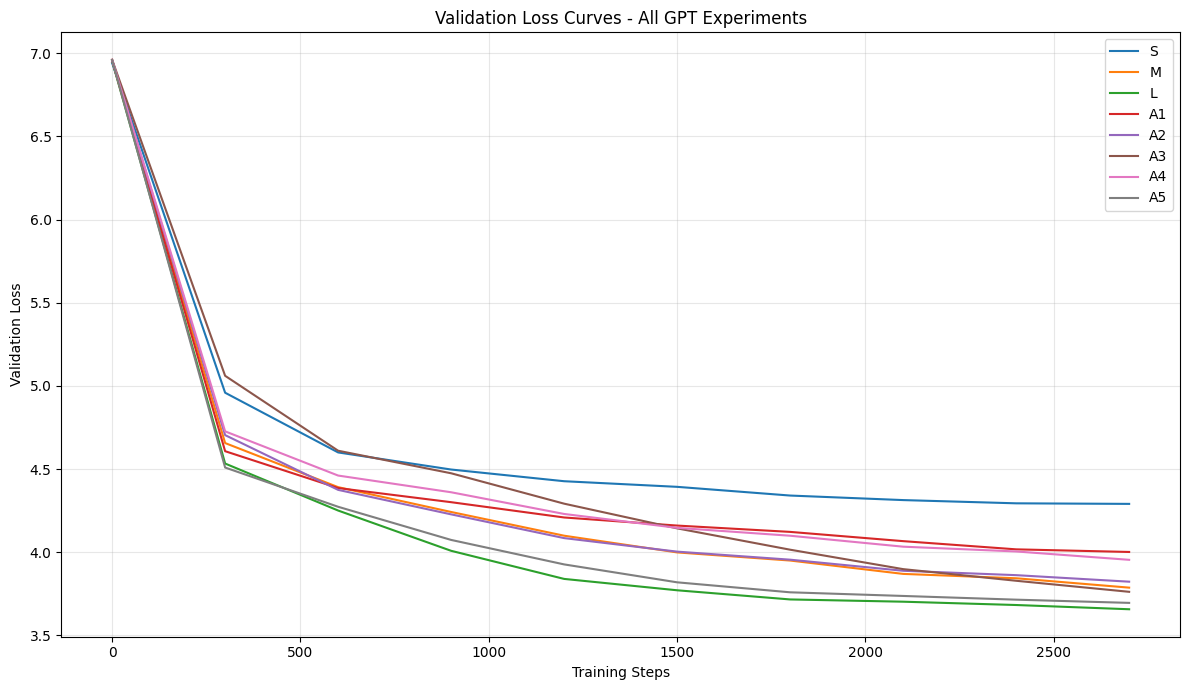

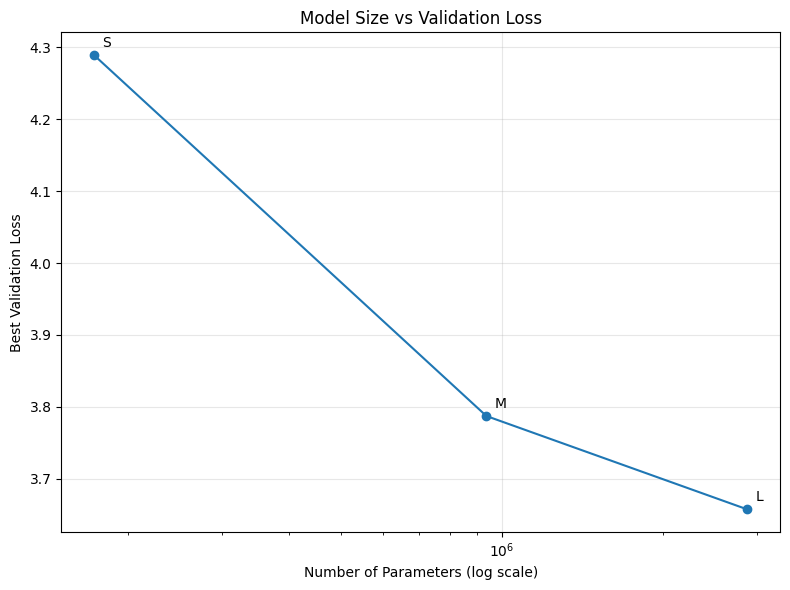

Both figures saved in: /content/drive/MyDrive/HW1_Aylin_Emiraslanova/figures


In [161]:
import os
import glob
import pandas as pd
import matplotlib.pyplot as plt

LOG_DIR = os.path.join(PROJECT_DIR, "logs")
FIGURE_DIR = os.path.join(PROJECT_DIR, "figures")
os.makedirs(FIGURE_DIR, exist_ok=True)

run_ids = ["S", "M", "L", "A1", "A2", "A3", "A4", "A5"]

# 1. Validation loss curves
plt.figure(figsize=(12, 7))

for run_id in run_ids:
    log_path = os.path.join(LOG_DIR, f"{run_id}.csv")

    if not os.path.exists(log_path):
        print("Log tapılmadı:", run_id)
        continue

    df = pd.read_csv(log_path)
    plt.plot(df["step"], df["val_loss"], label=run_id)

plt.xlabel("Training Steps")
plt.ylabel("Validation Loss")
plt.title("Validation Loss Curves - All GPT Experiments")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(os.path.join(FIGURE_DIR, "validation_curves.png"), dpi=300)
plt.show()


# 2. Parameters vs Best Validation Loss (S, M, L)
runs = pd.read_csv(os.path.join(PROJECT_DIR, "runs.csv"))
models = runs[runs["run_id"].isin(["S", "M", "L"])].copy()

plt.figure(figsize=(8, 6))
plt.plot(models["params"], models["best_val_loss"], marker="o")

for _, row in models.iterrows():
    plt.annotate(
        row["run_id"],
        (row["params"], row["best_val_loss"]),
        xytext=(6, 6),
        textcoords="offset points"
    )

plt.xscale("log")
plt.xlabel("Number of Parameters (log scale)")
plt.ylabel("Best Validation Loss")
plt.title("Model Size vs Validation Loss")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(os.path.join(FIGURE_DIR, "model_size_vs_loss.png"), dpi=300)
plt.show()

print("Both figures saved in:", FIGURE_DIR)

In [162]:
import sys
sys.path.append(PROJECT_DIR)

from tokenizer import BPETokenizer

tokenizer_path = os.path.join(PROJECT_DIR, "tokenizer.json")
tokenizer = BPETokenizer.load(tokenizer_path)

test_text = "Hello world! This is a GPT tokenizer test."
encoded = tokenizer.encode(test_text)
decoded = tokenizer.decode(encoded)

print("Original:", test_text)
print("Encoded:", encoded)
print("Decoded:", decoded)
print("Test passed:", decoded == test_text)

Original: Hello world! This is a GPT tokenizer test.
Encoded: [72, 395, 269, 516, 108, 100, 559, 878, 278, 575, 71, 80, 84, 400, 111, 107, 270, 817, 323, 116, 525, 46]
Decoded: Hello world! This is a GPT tokenizer test.
Test passed: True


In [164]:
import os

report_path = os.path.join(PROJECT_DIR, "reflection_notes.txt")

with open(report_path, "w") as f:
    f.write("""F1 - Most Costly Bug

Bug:
The tokenizer decoder could raise UnicodeDecodeError when the model generated
arbitrary byte sequences that did not form valid UTF-8 text.

Symptom:
Text generation could fail during decoding instead of returning a sample.

How it was fixed:
The decoder was updated to use UTF-8 decoding with errors="replace".
This preserves valid UTF-8 text and replaces invalid byte sequences instead
of crashing.

Verification:
A round-trip test was performed:
encode("Hello world! This is a GPT tokenizer test.")
decode(encoded) == original_text

The test passed.

Relevant file:
tokenizer.py

Git commit:
The current Git history does not yet identify a separate commit for this fix.
""")

print("F1 note saved:", report_path)

F1 note saved: /content/drive/MyDrive/HW1_Aylin_Emiraslanova/reflection_notes.txt


In [165]:
with open(report_path, "a") as f:
    f.write("""
F2 - Most Surprising Result

The most surprising result was A3, where the learning rate was increased
from 0.001 to 0.01. I expected the larger learning rate to make training
unstable, but the model did not diverge.

The baseline M achieved a best validation loss of 3.7872,
while A3 achieved 3.7621.

This suggests that, in this experiment, a higher learning rate
did not harm convergence and slightly improved validation performance.
However, the difference was small and does not prove that a higher
learning rate is generally better.
""")

print("F2 saved!")

F2 saved!


In [166]:
with open(report_path, "a") as f:
    f.write("""
F3 - Largest Design Effect

Removing positional embeddings had the largest negative effect
among the tested ablations.

The baseline M achieved a validation loss of 3.7872,
while A1 achieved 3.9783, an increase of 0.1911.

This indicates that positional information is important for
the model to learn the order of tokens in a sequence.

Increasing dropout to 0.2 also worsened performance:
A4 achieved 3.9545. In contrast, increasing batch size to 64
improved validation loss to 3.6956.
""")

print("F3 saved!")

F3 saved!


In [167]:
import os
import json
import torch
import sys

sys.path.append(PROJECT_DIR)

from model import GPT, GPTConfig
from generate import generate
from tokenizer import BPETokenizer

device = "cuda" if torch.cuda.is_available() else "cpu"

# Load tokenizer
tokenizer = BPETokenizer.load(
    os.path.join(PROJECT_DIR, "tokenizer.json")
)

# Load L configuration
with open(os.path.join(PROJECT_DIR, "configs", "L.json")) as f:
    config_data = json.load(f)

config = GPTConfig(
    vocab_size=1024,
    block_size=config_data["block_size"],
    n_layer=config_data["n_layer"],
    n_head=config_data["n_head"],
    n_embd=config_data["n_embd"],
    dropout=config_data["dropout"]
)

# Load trained L model
model = GPT(config).to(device)

checkpoint = torch.load(
    os.path.join(PROJECT_DIR, "checkpoints", "L_best.pt"),
    map_location=device
)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

# Generate 3 samples
prompt = "ROMEO:"
prompt_ids = tokenizer.encode(prompt)

samples = []

for seed in [42, 123, 456]:
    output_ids = generate(
        model,
        prompt_ids,
        max_new_tokens=120,
        temperature=0.8,
        use_cache=True,
        seed=seed
    )

    generated_text = tokenizer.decode(output_ids)
    samples.append(generated_text)

    print(f"\n{'='*50}\nSAMPLE - Seed {seed}\n")
    print(generated_text)

# Save samples
samples_path = os.path.join(PROJECT_DIR, "samples.txt")

with open(samples_path, "w") as f:
    for i, sample in enumerate(samples, 1):
        f.write(f"SAMPLE {i}\n{sample}\n\n")

print("\nAll 3 samples saved:", samples_path)


SAMPLE - Seed 42

ROMEO: this is off
His my sworth mock of Sicili John,
Coosure sisters forth to be follow us.
Your brother of your cause and need again.

First Lord:
For me, my lords, my lord, I had been,
I'll not send it out the meaner of my mother.
Bear me this news he would do both yourself;
And, if he came confess, that I
Might takes her h

SAMPLE - Seed 123

ROMEO: we what, till stands that now
As we find the chair of your blood, shall be all
As we must be past now: but we prithee now,
To remembrance the second as food of blood
Still your service,--

COMINIUS:
For it no cause. Let us do't.

CORIOLANUS:
Never sister marrive
A merid, or afliction: the more nurse
You might been

SAMPLE - Seed 456

ROMEO: and let my babout it,
He is every knee what to drown if
As fall upon this sudden. But now you must be
Now send you in our deed?

AUTOLYCUS:
And he's a capitol. The gods you all in the people,
Cominius he did still back the city shie-tink
common peat than his fire.

Clown:
Who has m

In [168]:
with open(report_path, "a") as f:
    f.write("""
F4 - Text Generation Analysis

Three samples of 120 new tokens were generated using the L model
with temperature 0.8.

The generated text contains Shakespeare-like vocabulary, dialogue
formatting, and character names. However, several limitations
are visible:

- Grammatical errors and incomplete phrases appear.
- Semantic coherence is weak in some passages.
- Words and expressions are sometimes repeated.
- Characters from different Shakespeare plays appear in the
  same generated continuation.

These problems may be related to the limited training dataset,
the model's relatively small capacity, and training for only
3000 steps. The model learns local language patterns but does
not consistently maintain long-range semantic coherence.
""")

print("F4 saved!")

F4 saved!


In [169]:
import os
import json
import torch

# Load tokenizer information
tokenizer_path = os.path.join(PROJECT_DIR, "tokenizer.json")

with open(tokenizer_path, "r") as f:
    tokenizer_data = json.load(f)

print("FIRST 10 MERGES:")
for i, merge in enumerate(tokenizer_data["merges"][:10]):
    print(i + 1, merge)

# Load trained tokenizer
tokenizer = BPETokenizer.load(tokenizer_path)

# Load validation token IDs
val_path = os.path.join(PROJECT_DIR, "cache", "val_tokens.pt")
val_tokens = torch.load(val_path, map_location="cpu", weights_only=False)

if isinstance(val_tokens, torch.Tensor):
    val_ids = val_tokens.tolist()
else:
    val_ids = list(val_tokens)

# Decode validation text
val_text = tokenizer.decode(val_ids)

# Calculate bytes per token
total_bytes = len(val_text.encode("utf-8"))
total_tokens = len(val_ids)

bytes_per_token = total_bytes / total_tokens

print("\nVALIDATION STATISTICS")
print("Total bytes:", total_bytes)
print("Total tokens:", total_tokens)
print("Bytes per token:", round(bytes_per_token, 4))

FIRST 10 MERGES:
1 [101, 32]
2 [116, 104]
3 [116, 32]
4 [115, 32]
5 [100, 32]
6 [44, 32]
7 [111, 117]
8 [101, 114]
9 [105, 110]
10 [121, 32]

VALIDATION STATISTICS
Total bytes: 111540
Total tokens: 46702
Bytes per token: 2.3883


In [170]:
with open(report_path, "a") as f:
    f.write("""
F5 - Tokenizer Analysis

The first ten BPE merges were:
1. (101, 32) -> "e "
2. (116, 104) -> "th"
3. (116, 32) -> "t "
4. (115, 32) -> "s "
5. (100, 32) -> "d "
6. (44, 32) -> ", "
7. (111, 117) -> "ou"
8. (101, 114) -> "er"
9. (105, 110) -> "in"
10. (121, 32) -> "y "

These merges show that frequent English character combinations
and common letter-space patterns are combined into larger tokens.

The validation text contained 111,540 bytes and 46,702 tokens,
resulting in 2.3883 bytes per token.
""")

print("F5 saved!")

F5 saved!


In [171]:
import os

print("PROJECT FILES:\n")

for root, dirs, files in os.walk(PROJECT_DIR):
    dirs[:] = [d for d in dirs if d not in ["__pycache__", ".git"]]

    level = root.replace(PROJECT_DIR, "").count(os.sep)
    indent = " " * 4 * level

    print(f"{indent}{os.path.basename(root)}/")

    for file in files:
        print(f"{indent}    {file}")

print("\nGIT STATUS:")
os.chdir(PROJECT_DIR)
!git status --short

print("\nGIT HISTORY:")
!git log --oneline --date=short --pretty=format:"%h %ad %s" -10

PROJECT FILES:

HW1_Aylin_Emiraslanova/
    .gitignore
    README.md
    tokenizer.py
    tokenizer.json
    model.py
    bigram.py
    train.py
    generate.py
    runs.csv
    reflection_notes.txt
    samples.txt
    checkpoints/
        best_model.pt
        TEST_best.pt
        S_best.pt
        M_best.pt
        L_best.pt
        A1_best.pt
        A2_best.pt
        A3_best.pt
        A4_best.pt
        A5_best.pt
    configs/
        M.json
        TEST.json
        A1.json
        A2.json
        A3.json
        A4.json
        A5.json
        S.json
        L.json
    cache/
        train_tokens.pt
        val_tokens.pt
    logs/
        TEST.csv
        S.csv
        M.csv
        L.csv
        A1.csv
        A2.csv
        A3.csv
        A4.csv
        A5.csv
    figures/
        validation_curves.png
        model_size_vs_loss.png

GIT STATUS:
 M model.py
 M tokenizer.py
?? bigram.py
?? configs/
?? figures/
?? generate.py
?? logs/
?? reflection_notes.txt
?? runs.csv
?? samp

In [176]:

import os
from reportlab.lib import colors
from reportlab.lib.pagesizes import A4
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.lib.enums import TA_CENTER
from reportlab.lib.units import cm
from reportlab.platypus import (
    SimpleDocTemplate, Paragraph, Spacer, Table, TableStyle,
    Image, PageBreak
)

report_path = os.path.join(PROJECT_DIR, "report.pdf")
figures = os.path.join(PROJECT_DIR, "figures")

doc = SimpleDocTemplate(
    report_path,
    pagesize=A4,
    rightMargin=1.6*cm,
    leftMargin=1.6*cm,
    topMargin=1.5*cm,
    bottomMargin=1.5*cm
)

styles = getSampleStyleSheet()
styles.add(ParagraphStyle(
    name="ReportTitle", parent=styles["Title"],
    fontSize=19, leading=23, alignment=TA_CENTER,
    spaceAfter=10
))
styles.add(ParagraphStyle(
    name="Section", parent=styles["Heading2"],
    fontSize=12, leading=15, spaceBefore=8, spaceAfter=5
))
styles.add(ParagraphStyle(
    name="SmallText", parent=styles["BodyText"],
    fontSize=8.5, leading=11
))

story = []

def P(text, style="BodyText"):
    story.append(Paragraph(text, styles[style]))

def section(text):
    P(text, "Section")

# PAGE 1
P("HW1: BUILD A GPT FROM SCRATCH", "ReportTitle")
P("<b>Student:</b> Aylin Emiraslanova")
P("<b>Project:</b> Character-level Byte Pair Encoding and GPT Language Model")
P("<b>Framework:</b> Python and PyTorch")
P("<b>Dataset:</b> Tiny Shakespeare")
story.append(Spacer(1, 8))

section("1. Introduction")
P(
    "The objective of this project was to implement a small GPT-style "
    "autoregressive language model from scratch using PyTorch. The project "
    "includes a byte-level BPE tokenizer, a decoder-only Transformer, "
    "a training pipeline, text generation with sampling strategies, "
    "and a key-value cache for faster inference."
)

section("2. Dataset and Tokenizer")
P(
    "The Tiny Shakespeare dataset contains 1,115,394 characters. "
    "The first 90% (1,003,854 characters) was used for training and "
    "the final 10% (111,540 characters) for validation. The tokenizer "
    "was trained only on the training portion to avoid validation leakage."
)
P(
    "A byte-level BPE tokenizer was implemented with a base vocabulary "
    "of 256 byte values and 768 merge operations, producing a vocabulary "
    "of 1,024 tokens. The validation set contained 46,702 tokens and "
    "111,540 bytes, corresponding to 2.3883 bytes per token."
)

section("3. Model Architecture")
P(
    "The GPT model uses token and positional embeddings, causal "
    "self-attention, feed-forward MLP blocks, residual connections, "
    "LayerNorm, and a language-model output head. The baseline M model "
    "uses 4 Transformer layers, 4 attention heads, an embedding dimension "
    "of 128, and a context length of 128. The output weights are tied "
    "to the token embedding weights."
)

section("4. Training Setup")
P(
    "Models were trained using AdamW with betas (0.9, 0.95), weight decay "
    "0.1 for parameters with at least two dimensions, gradient clipping "
    "at 1.0, and a warmup followed by cosine learning-rate decay. "
    "The experiments used 3,000 training steps, a context length of 128, "
    "and a warmup of 137 steps."
)

# PAGE 2
story.append(PageBreak())
section("5. Experimental Results")
P(
    "Eight GPT experiments were completed: three model sizes (S, M, L) "
    "and five controlled ablations (A1-A5). The best validation losses "
    "are summarized below. The Bigram baseline uses add-one smoothing."
)

result_data = [
    ["Run", "Description", "Parameters", "Best val. loss"],
    ["Bigram", "Add-one smoothed baseline", "—", "4.9260"],
    ["S", "2 layers, 2 heads, d=64", "172,672", "4.2894"],
    ["M", "4 layers, 4 heads, d=128", "936,192", "3.7872"],
    ["L", "6 layers, 6 heads, d=192", "2,880,384", "3.6573"],
    ["A1", "No positional embeddings", "919,808", "3.9783"],
    ["A2", "Post-LayerNorm", "936,192", "3.8230"],
    ["A3", "Learning rate = 0.01", "936,192", "3.7621"],
    ["A4", "Dropout = 0.2", "936,192", "3.9545"],
    ["A5", "Batch size = 64", "936,192", "3.6956"],
]

t = Table(result_data, colWidths=[1.5*cm, 7.1*cm, 3.0*cm, 3.0*cm])
t.setStyle(TableStyle([
    ("BACKGROUND", (0,0), (-1,0), colors.HexColor("#263B5A")),
    ("TEXTCOLOR", (0,0), (-1,0), colors.white),
    ("FONTNAME", (0,0), (-1,0), "Helvetica-Bold"),
    ("FONTSIZE", (0,0), (-1,-1), 8),
    ("GRID", (0,0), (-1,-1), 0.4, colors.grey),
    ("ROWBACKGROUNDS", (0,1), (-1,-1),
     [colors.white, colors.HexColor("#EEF2F7")]),
    ("VALIGN", (0,0), (-1,-1), "MIDDLE"),
    ("LEFTPADDING", (0,0), (-1,-1), 5),
    ("RIGHTPADDING", (0,0), (-1,-1), 5),
    ("TOPPADDING", (0,0), (-1,-1), 5),
    ("BOTTOMPADDING", (0,0), (-1,-1), 5),
]))
story.append(t)

section("6. Interpretation")
P(
    "The L model achieved the lowest validation loss (3.6573), followed "
    "by A5 (3.6956). All GPT configurations performed better than the "
    "Bigram baseline. The best GPT result is approximately 25.8% lower "
    "than the Bigram validation loss, exceeding the required 10% margin."
)
P(
    "Removing positional embeddings increased the validation loss from "
    "3.7872 (M) to 3.9783 (A1), showing the importance of positional "
    "information. Increasing dropout to 0.2 also worsened the result. "
    "A3, with a ten-times higher learning rate, remained stable and "
    "slightly outperformed M. A5, using batch size 64, improved the "
    "validation loss to 3.6956."
)

section("7. Validation Curves")
curve_path = os.path.join(figures, "validation_curves.png")
if os.path.exists(curve_path):
    img = Image(curve_path, width=16.5*cm, height=9.0*cm)
    story.append(img)
else:
    P("Validation curve image was not found.")

# PAGE 3
story.append(PageBreak())
section("8. Model Size versus Validation Loss")
size_path = os.path.join(figures, "model_size_vs_loss.png")
if os.path.exists(size_path):
    img = Image(size_path, width=14.5*cm, height=10.5*cm)
    story.append(img)
else:
    P("Model size plot was not found.")

section("9. Inference and KV Cache")
P(
    "The generation function supports temperature sampling, top-k, top-p, "
    "greedy decoding, reproducible seeds, and optional KV caching. "
    "The cached and uncached next-token logits were tested for numerical "
    "agreement. In a 120-token generation benchmark on the M model, "
    "KV caching achieved approximately 480 tokens/second compared with "
    "415 tokens/second without caching, giving a speedup of about 1.16x."
)

section("10. Generated Text Evaluation")
P(
    "Three samples of 120 new tokens were generated from the L model "
    "using the prompt 'ROMEO:' and temperature 0.8. The generated text "
    "contains Shakespeare-like vocabulary, dialogue formatting, and "
    "character names. However, it also exhibits grammatical errors, "
    "incomplete phrases, repetition, and character names from different "
    "plays. The model captures local stylistic patterns but does not "
    "consistently maintain long-range semantic coherence."
)
P(
    "These limitations may be related to the limited dataset, model "
    "capacity, context length, and the relatively short training schedule."
)

section("11. Reflection")
P(
    "<b>F1 - Costly bug:</b> Invalid UTF-8 byte sequences during generation "
    "could raise UnicodeDecodeError. The decoder was changed to use "
    "errors='replace'. A valid-text encode/decode round-trip test passed."
)
P(
    "<b>F2 - Surprising result:</b> A3 did not diverge despite increasing "
    "the learning rate from 0.001 to 0.01. Its best validation loss was "
    "3.7621 compared with 3.7872 for M."
)
P(
    "<b>F3 - Largest effect:</b> Removing positional embeddings had the "
    "largest negative effect among the tested ablations, increasing "
    "validation loss by 0.1911."
)
P(
    "<b>F4 - Generation:</b> The samples showed local Shakespeare-like "
    "patterns but weak semantic consistency and occasional repetition."
)
P(
    "<b>F5 - Tokenizer:</b> The first merges included 'e ', 'th', 't ', "
    "'s ', 'd ', ', ', 'ou', 'er', 'in', and 'y '. These frequent English "
    "patterns are reasonable BPE merges. Validation efficiency was "
    "2.3883 bytes per token."
)

# PAGE 4
story.append(PageBreak())
section("12. Reproducibility and Project Files")
P(
    "Training configurations are stored in the configs directory. "
    "Per-run training and validation metrics are stored in logs as CSV "
    "files, and the aggregate experiment table is stored in runs.csv. "
    "Generated samples are stored in samples.txt. The tokenizer "
    "vocabulary and merge rules are stored in tokenizer.json."
)
P(
    "The experiment identifiers used in the analysis are S, M, L, "
    "A1, A2, A3, A4, and A5. Their corresponding training records are "
    "logs/S.csv, logs/M.csv, logs/L.csv, and logs/A1.csv through logs/A5.csv."
)

section("13. Conclusion")
P(
    "This project implemented and evaluated a GPT-style language model "
    "from low-level PyTorch components. The experiments demonstrate "
    "that model size, positional information, dropout, learning rate, "
    "and batch size can affect language-model validation performance. "
    "The best GPT model substantially outperformed the smoothed Bigram "
    "baseline. The generated samples also demonstrate the limitations "
    "of a small model trained on a limited corpus."
)

section("14. References")
P(
    "Dataset: Tiny Shakespeare, "
    "https://github.com/karpathy/char-rnn/tree/master/data/tinyshakespeare"
)
P(
    "Framework: PyTorch documentation, https://pytorch.org/docs/"
)
P(
    "All numerical results in this report are taken from the project's "
    "runs.csv and individual training logs."
)

doc.build(story)

print("Report created successfully!")
print("Path:", report_path)
print("Size:", round(os.path.getsize(report_path) / 1024, 1), "KB")


Report created successfully!
Path: /content/drive/MyDrive/HW1_Aylin_Emiraslanova/report.pdf
Size: 533.9 KB


In [175]:
!pip install reportlab

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 5.1 MB/s  0:00:00


In [178]:
import subprocess

result = subprocess.run(
    ["git", "log", "--date=short", "--pretty=format:%ad", "--all"],
    cwd=TEST_DIR,
    capture_output=True,
    text=True
)

print(result.stdout)

2026-11-20
